# Análise exploratória de dados

Esse notebook organiza nosso processo e nossos achados durante a fase de exploração dos dados do projeto; nós o criamos após termos feito boa parte da análise para fins de avaliação por parte dos professores.
Caso queiram olhar a versão original (bem mais desorganizada), ela se encontra em [`EDA/com_pedidos.ipynb`](EDA/com_pedidos.ipynb).

**Disclaimer**: durante o processo de exploração dos dados, nós acabamos não separando o conjunto de dados em treino, validação e teste, assim, fizemos a análise no conjunto completo. Pensávamos que o problema de vazamento de dados se limitava ao pré-processamento e não levamos em consideração que, ao analisar métricas relacionadas ao conjunto como um todo, a presença dos futuros dados de treino e validação poderia enviesar nossas conclusões com base em informações às quais não deveríamos ter acesso. Após conversarmos com o professor Paulo, decidimos incluir esse aviso por transparência e para registrar nosso aprendizado durante o projeto. Faremos essa ressalva novamente quando for relevante.

---

### Setup do notebook

Importando as dependências necessárias:

In [1]:
import pprint
import re

import matplotlib.pyplot as plot
import numpy as np
import pandas as pd
import seaborn as sb
from scipy import stats

# Configurando o estilo dos gráficos que criaremos:
sb.set_theme(style='ticks', palette='Set2')

Vamos carregar os dados fornecidos agora.

In [2]:
leads = pd.read_csv('data/churn_aplicacao_leads_final.csv')
pedidos = pd.read_csv('data/churn_comportamental_pedidos_final.csv')

Iremos também efetuar um "join" para cruzar os dados dos pedidos com os clientes na tabela de leads fornecida:

In [3]:
clientes_com_pedidos = leads.merge(right=pedidos, on='id_cliente', how='left')

---


## 1. Análise estrutural

Usaremos o método `info()` nos DataFrames para ter uma visão geral dos dados:

In [4]:
leads.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 19 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   id_cliente                       2000 non-null   int64  
 1   uf                               2000 non-null   object 
 2   municipio                        2000 non-null   object 
 3   segmento_cliente                 2000 non-null   object 
 4   natureza_juridica                2000 non-null   object 
 5   fonte_cliente                    2000 non-null   object 
 6   cnae_codigo                      2000 non-null   object 
 7   capital_social                   2000 non-null   object 
 8   idade_cnpj                       2000 non-null   object 
 9   serasa_contagem_negativacoes     2000 non-null   float64
 10  serasa_contagem_protestos        2000 non-null   float64
 11  serasa_credores                  190 non-null    object 
 12  serasa_socio_tem_neg

- Temos 2000 amostras nessa tabela.
- Existem 19 atributos, a maioria dos quais aparenta ser categórico.
- Os seguintes campos aparentam ter dados faltantes:
    - `serasa_credores`;
    - `ifood_contagem_avaliacoes`;
    - `ifood_faixa_preco`;
    - `google_maps_avaliacao`;
    - `google_maps_contagem_avaliacoes`; e
    - `google_maps_tem_website`.
- Fora esses valores que devemos averiguar, todos os outros parecem estar completos, basta verificar se as amostras são únicas mesmo.

In [5]:
pedidos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4441 entries, 0 to 4440
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   id_pedido     4441 non-null   int64 
 1   id_cliente    4441 non-null   int64 
 2   valor         4438 non-null   object
 3   produtos      4440 non-null   object
 4   data_entrega  4441 non-null   object
dtypes: int64(2), object(3)
memory usage: 173.6+ KB


- Temos uma tabela com bem menos atributos, uma vez que 2 dos 5 são identificadores.
- Existem muito mais pedidos que clientes, mas esses pedidos são de clientes diferentes ou são vários de um cliente só?
- `valor` e `produtos` têm alguns valores faltantes.
- `data_entrega` deve representar uma data, apesar do tipo inferido pelo pandas ser `str`.
    - Significa dizer que o comportamento dos clientes é registrado em uma série temporal.

Vamos entender se os pedidos são diversos entre os clientes registrados.

In [6]:
print(f'Quantidade de clientes sem pedidos: {clientes_com_pedidos.id_pedido.isna().sum()}\n')

print('Quantidade de pedidos por cliente (>0):')
pedidos.id_cliente.value_counts()

Quantidade de clientes sem pedidos: 1000

Quantidade de pedidos por cliente (>0):


id_cliente
1739936841220    56
8113331192324    46
7243866379881    44
1560063946241    29
1222295907587    29
                 ..
6388676592025     1
1972150366050     1
2150548890639     1
5283377970744     1
1834318012896     1
Name: count, Length: 1000, dtype: int64

Tudo indica que é relativamente diverso, definitivamente não há o problema de apenas um cliente ter a maioria dos pedidos.

O objetivo do nosso futuro modelo será prever a probabilidade de um cliente dar churn, logo `churned` é nosso atributo-alvo.

Vamos ver a quantidade de amostras da tabela de **leads** com `churned == 0` e `churned == 1`:

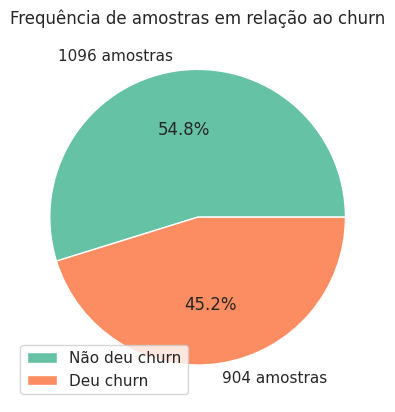

In [7]:
contagem_de_churned = leads.churned.value_counts()

plot.title('Frequência de amostras em relação ao churn')
plot.pie(contagem_de_churned, labels=[f'{contagem} amostras' for contagem in contagem_de_churned], autopct='%.1f%%')
plot.legend(['Não deu churn', 'Deu churn'])
plot.show()

Existem mais clientes que não deram churn que o contrário, mas não a ponto de termos pouquíssimos exemplos.

Vamos ver agora quais são os valores possíveis para cada atributo nos conjuntos:

In [8]:
def print_unique_count(table: pd.DataFrame, table_name: str, max_count: int = 20):
    print(f'Valores únicos dos atributos de {table_name}:')

    for label in table.columns:
        column: pd.Series = table[label]

        unique_values = column.unique()
        print(f'{label:32s} | {unique_values.size!s:5s}', end='')

        # Imprimindo os valores possíveis para
        # os atributos somente se são poucos:
        if unique_values.size <= max_count:
            values_str = ', '.join(str(v) for v in unique_values)
            print(f'({values_str})', end='')

        print()

print_unique_count(leads, 'leads', max_count=32)
print()
print_unique_count(pedidos, 'pedidos')

Valores únicos dos atributos de leads:
id_cliente                       | 2000 
uf                               | 1    (CE)
municipio                        | 31   (FORTALEZA, MARACANAU, CAUCAIA, AQUIRAZ, EUSEBIO, PINDORETAMA, HORIZONTE, MARANGUAPE, CASCAVEL, PACAJUS, PACATUBA, SAO GONCALO DO AMARANTE, ITAITINGA, REDENCAO, GUAIUBA, ARACOIABA, ACARAPE, CHOROZINHO, BATURITE, PACOTI, GUARAMIRANGA, PARACURU, ARACATI, PARAIPABA, AMONTADA, BARREIRA, TURURU, PALMACIA, BARBARA BEATRIZ QUEIROZ DE SOUSA 60464662370, JIJOCA DE JERICOACOARA, CRUZ)
segmento_cliente                 | 21   (Segmento 5, Segmento 19, Segmento 20, Segmento 13, Segmento 18, Segmento 14, Segmento 3, Segmento 10, Segmento 15, Segmento 4, Segmento 16, Segmento 8, Segmento 6, Segmento 9, Segmento 17, Segmento 2, Segmento 21, Segmento 7, Segmento 1, Segmento 11, Segmento 12)
natureza_juridica                | 4    (206-2 - Sociedade Empresária Limitada, 213-5 - Empresário (Individual), 230-5 - Empresa Individual de Responsab

- **O atributo `uf` é irrelevante**, pois todos os dados do nosso conjunto são de apenas um estado. Devemos descartá-lo na fase de pré-processamento.
- Boa parte dos valores são categóricos, com a maioria desses sendo intervalos de valores bem ordenados.
- O atributo `google_maps_tem_website` é uma flag booleana que representa `true` como `1` e `false` como `nan`.

Olhamos também os valores únicos para `serasa_credores`:

In [9]:
serasa_credores_unicos = leads.serasa_credores.dropna().unique()

print('Valores únicos para o atributo serasa_credores:')
pprint.pp(sorted(serasa_credores_unicos))

Valores únicos para o atributo serasa_credores:
['Alimentos e Bebidas',
 'Alimentos e Bebidas, Alimentos e Bebidas, Alimentos e Bebidas',
 'Alimentos e Bebidas, Bancos e Financeiro',
 'Alimentos e Bebidas, Bancos e Financeiro, Alimentos e Bebidas',
 'Alimentos e Bebidas, Bancos e Financeiro, Bancos e Financeiro, Financeiro, '
 'Alimentos e Bebidas, Alimentos e Bebidas, Indústria',
 'Alimentos e Bebidas, Saúde',
 'Alimentos e Bebidas, Tecnologia e Pagamentos',
 'Bancos e Financeiro',
 'Bancos e Financeiro, Alimentos e Bebidas, Bancos e Financeiro',
 'Bancos e Financeiro, Alimentos e Bebidas, Distribuição',
 'Bancos e Financeiro, Bancos e Financeiro',
 'Bancos e Financeiro, Bancos e Financeiro, Bancos e Financeiro',
 'Bancos e Financeiro, Bancos e Financeiro, Telecomunicações, Contabilidade',
 'Bancos e Financeiro, Comunicação',
 'Bancos e Financeiro, Financeiro',
 'Bancos e Financeiro, Tecnologia e Pagamentos',
 'Bancos e Financeiro, Tecnologia e Pagamentos, Bancos e Financeiro',
 'Comu

Como os valores dessa coluna são listas separadas por vírgulas, alguns tem 'e' no próprio nome, mas o separador real é apenas a vírgula. Podemos consultar os *tipos de credor* únicos da seguinte forma:

In [10]:
tipos_credores_unicos: set[str] = set()
for lista_credores in serasa_credores_unicos:
    tipos_credores_unicos.update(lista_credores.split(', '))

print('Tipos de credores únicos registrados no atributo serasa_credores:')
pprint.pp(tipos_credores_unicos)

Tipos de credores únicos registrados no atributo serasa_credores:
{'Alimentos e Bebidas',
 'Bancos e Financeiro',
 'Comunicação',
 'Comércio',
 'Contabilidade',
 'Distribuição',
 'Diversos',
 'Energia',
 'Financeiro',
 'Imobiliário',
 'Indústria',
 'Logística',
 'Saúde',
 'Seguros e Financeiro',
 'Serviços',
 'Serviços Ambientais',
 'Tecnologia',
 'Tecnologia e Pagamentos',
 'Telecomunicações',
 'Varejo',
 'Viagens e Turismo'}


Vamos verificar quais são as porcentagens de faltas nos atributos observados anteriormente:

In [11]:
def print_missing_pct(table: pd.DataFrame, table_name: str):
    print(f'Porcentagem de faltas nos atributos de {table_name}:')

    for label in table.columns:
        column: pd.Series = table[label]
        missing_pct = 100 * column.isna().sum() / column.size
        
        if missing_pct > 0:
            print(f'{label:32s} | {missing_pct:.2f}% ({column.isna().sum()}/{column.size})')

print_missing_pct(leads, 'leads')
print()
print_missing_pct(pedidos, 'pedidos')

Porcentagem de faltas nos atributos de leads:
serasa_credores                  | 90.50% (1810/2000)
ifood_contagem_avaliacoes        | 94.30% (1886/2000)
ifood_faixa_preco                | 87.85% (1757/2000)
google_maps_avaliacao            | 97.80% (1956/2000)
google_maps_contagem_avaliacoes  | 91.25% (1825/2000)
google_maps_tem_website          | 91.25% (1825/2000)

Porcentagem de faltas nos atributos de pedidos:
valor                            | 0.07% (3/4441)
produtos                         | 0.02% (1/4441)


Vamos observar primeiro a tabela de **leads**:
- Pelo documento no Notion, os valores de `serasa_credores` são listas separadas por vírgulas dos tipos de credores do cliente. Ou seja, ter um valor nulo de `serasa_credores` implica não ter nenhum credor, assim, a falta do valor tem uma semântica bem definida.
- Os atributos `ifood_contagem_avaliacoes` e `ifood_faixa_preco` são nulos se o cliente não possui nenhuma conta no iFood. Pelo o que entendemos, a Praso não atende exclusivamente restaurantes, mas também fornecem seus serviços para outros comércios que não são comuns no iFood (como supermercados, já que apenas as grandes cadeias têm entregas pelo iFood), logo, esses atributos não trazem muitas informações sobre a população como um todo. Podem valer a pena manter se tiverem uma grande correlação com o atributo-alvo, mas se não tiverem, talvez seja mais relevante apenas saber se o cliente tem iFood ou não.
- As faltas no atributo `google_maps_tem_website` têm semântica clara como visto anteriormente. Ademais, se o estabelecimento não está registrado no Google Maps, terá 0 avaliações. O intervalo desse atributo de menores fronteiras é `(0, 5]`, o qual não inclui diretamente o número 0. Se formos usar esse atributo, podemos usar desse fato para criar uma nova categoria. 
- Além disso, `google_maps_avaliacao` tem valor em apenas 2.2% das amostras (a menor quantidade de todas), e a falta desses valores não tem semântica clara. Pela falta de dados, isso pode inviablizar seu uso no modelo.

A tabela de **pedidos** tem pouquíssimos valores faltantes. Nós acabamos vendo as amostras que tinham esses valores faltantes (note que sabemos que, do jeito que fizemos, **isso não é uma boa ideia**, vide o disclaimer):

In [12]:
pedidos[pedidos.valor.isna() | pedidos.produtos.isna()]

,id_pedido,id_cliente,valor,produtos,data_entrega
1754,3651192517370,5284965822687,NaN,"(0, 5]",2024-11-07
3566,8540620592324,6829726356717,NaN,"(0, 5]",2024-10-06
3603,9279195172130,8400679696018,NaN,NaN,2024-09-10


Pela pouca quantidade, e sabendo dos valores possíveis para `valor` e `produtos` (são categóricos), podemos imputar potenciais valores faltantes nessas colunas usando a **moda** dos valores correspondentes dos pedidos feitos pelo cliente. **Levaremos isso em conta somente quando separarmos os conjuntos e partimos para o pré-processamento dos dados.**

Por fim, analisamos a temporalidade da tabela de pedidos, vendo em qual intervalo de tempo o conjunto registrou amostras:

In [13]:
primeira_data = pedidos.data_entrega.min()
ultima_data = pedidos.data_entrega.max()

print(f'Intervalo de tempo: {primeira_data} ---- {ultima_data}')

Intervalo de tempo: 2024-09-01 ---- 2024-12-01


Como confirmado pela Praso, os dados se referem ao último trimestre de 2024.

---

## 2. Análise univariada


Vamos tentar compreender melhor a distribuição de cada atributo, separando a análise em duas partes: primeiro o **perfil cadastral dos leads** (2.1) e depois o **comportamento de pedidos** (2.2).

Começamos pelos atributos categóricos que armazenam intervalos de valores numéricos. Criamos duas funções auxiliares: uma para ordenar esses intervalos corretamente e outra para plotar dois atributos desse tipo lado a lado.


In [14]:
def sort_by_range(values: list[str], *, is_float = False):
    """Ordena intervalos numéricos escritos por extenso"""

    range_type = float if is_float else int
    
    ranges = sorted(
        [range_type(v) for v in range[1:-1].split(', ')]
        for range in values
    )

    return [
        f'({a}, {b}]' for a, b in ranges
    ]

In [15]:
def plot_ranged_countplot1x2(data: pd.DataFrame, features: tuple[str, str], show_avg_count: bool = False):
    axes = plot.figure(figsize=(20, 10)).subplots(1, 2)

    for i in range(2):
        feature, ax = features[i], axes[i % 2]
        is_float = feature in ('google_maps_avaliacao') # só esse atributo tem intervalo em floats

        ranges = sort_by_range(data[feature].dropna().unique(), is_float=is_float)
        sb.countplot(
            data=data,
            y=feature,
            order=ranges,
            ax=ax
        )
        if show_avg_count:
            ax.plot(
                [data[feature].value_counts().mean() for _ in ranges],
                ranges,
                linestyle='--',
                color='black',
            )
            ax.legend(['Contagem média'])

### 2.1 Perfil dos leads

Analisamos a distribuição dos atributos cadastrais da tabela de leads.


#### Capital social e idade do CNPJ


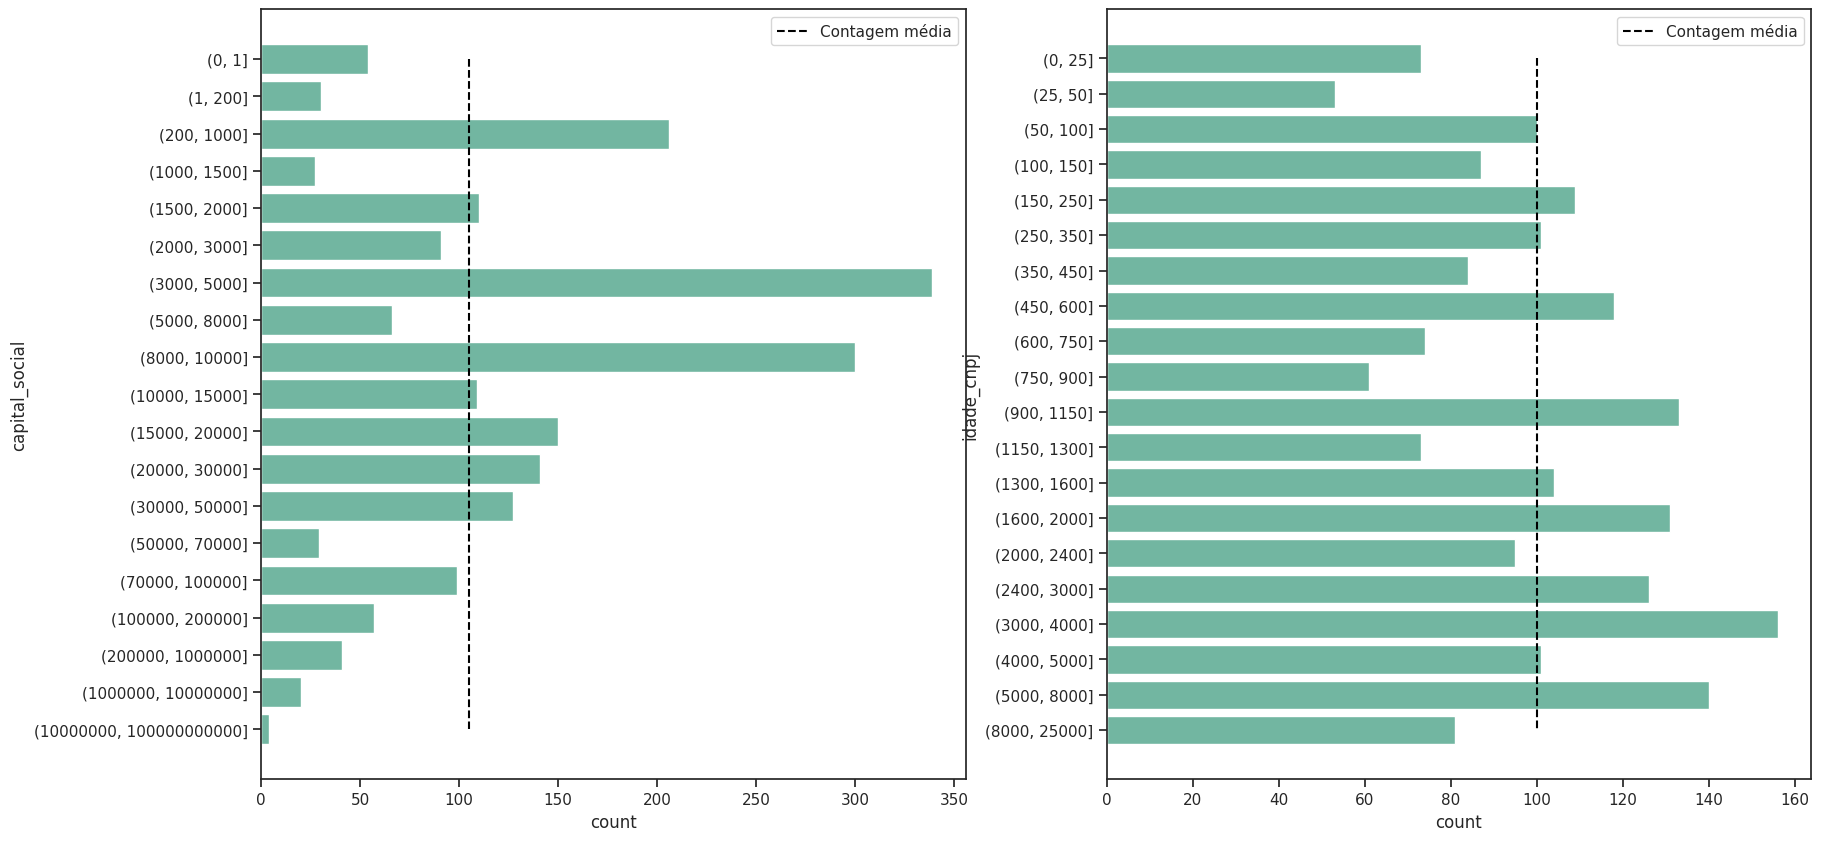

In [16]:
plot_ranged_countplot1x2(leads, ('capital_social', 'idade_cnpj'), show_avg_count=True)

Vemos que os clientes no conjunto têm uma boa diversidade no que tange ao capital social e à idade do CNPJ; em ambos atributos, temos categorias com valores abaixo e acima da média por margens significativas.

Em geral, os clientes registrados tem capital social na faixa de 3000 a 10000 e os seus CNPJs tendem a ser um pouquinho mais velhos que novos.

#### Avaliações no Google Maps e no iFood


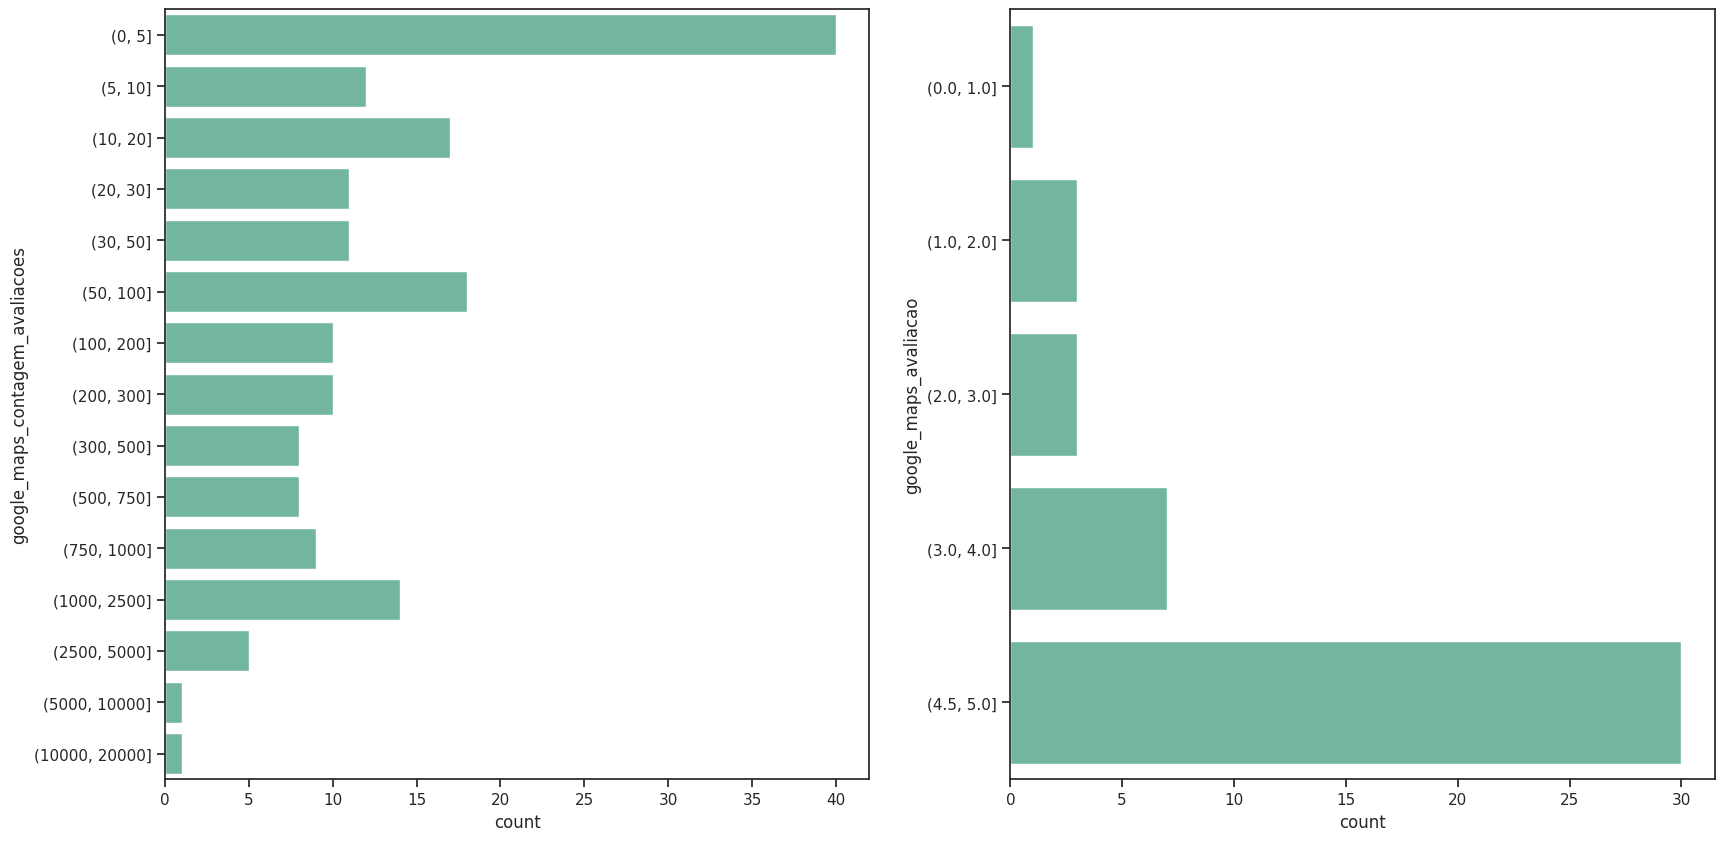

In [17]:
plot_ranged_countplot1x2(leads, ('google_maps_contagem_avaliacoes', 'google_maps_avaliacao'))

Em relação aos poucos clientes que têm cadastro no Google Maps, há um padrão mais claro. Os estabelecimentos que têm website no Google Maps tendem a ser mais bem avaliados, mas não têm muitas avaliações. Isso pode significar que a avaliação registrada não é o consenso exato de todos os usuários do serviço do cliente, e talvez para alguns a avaliação diminuiria se mais pessoas as fizessem no Google Maps.

<Axes: xlabel='count', ylabel='ifood_contagem_avaliacoes'>

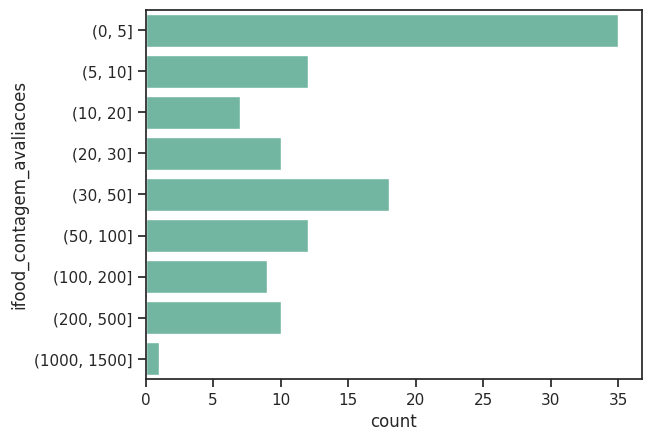

In [18]:
sb.countplot(
    data=leads,
    y='ifood_contagem_avaliacoes',
    order=sort_by_range(leads.ifood_contagem_avaliacoes.dropna().unique()),
)

Já no que tange à contagem de avaliações no iFood, o padrão é similar àquele observado na contagem do Google Maps, já que de fato consumidores tendem a dar poucas avaliações.

#### Fonte e segmento do cliente


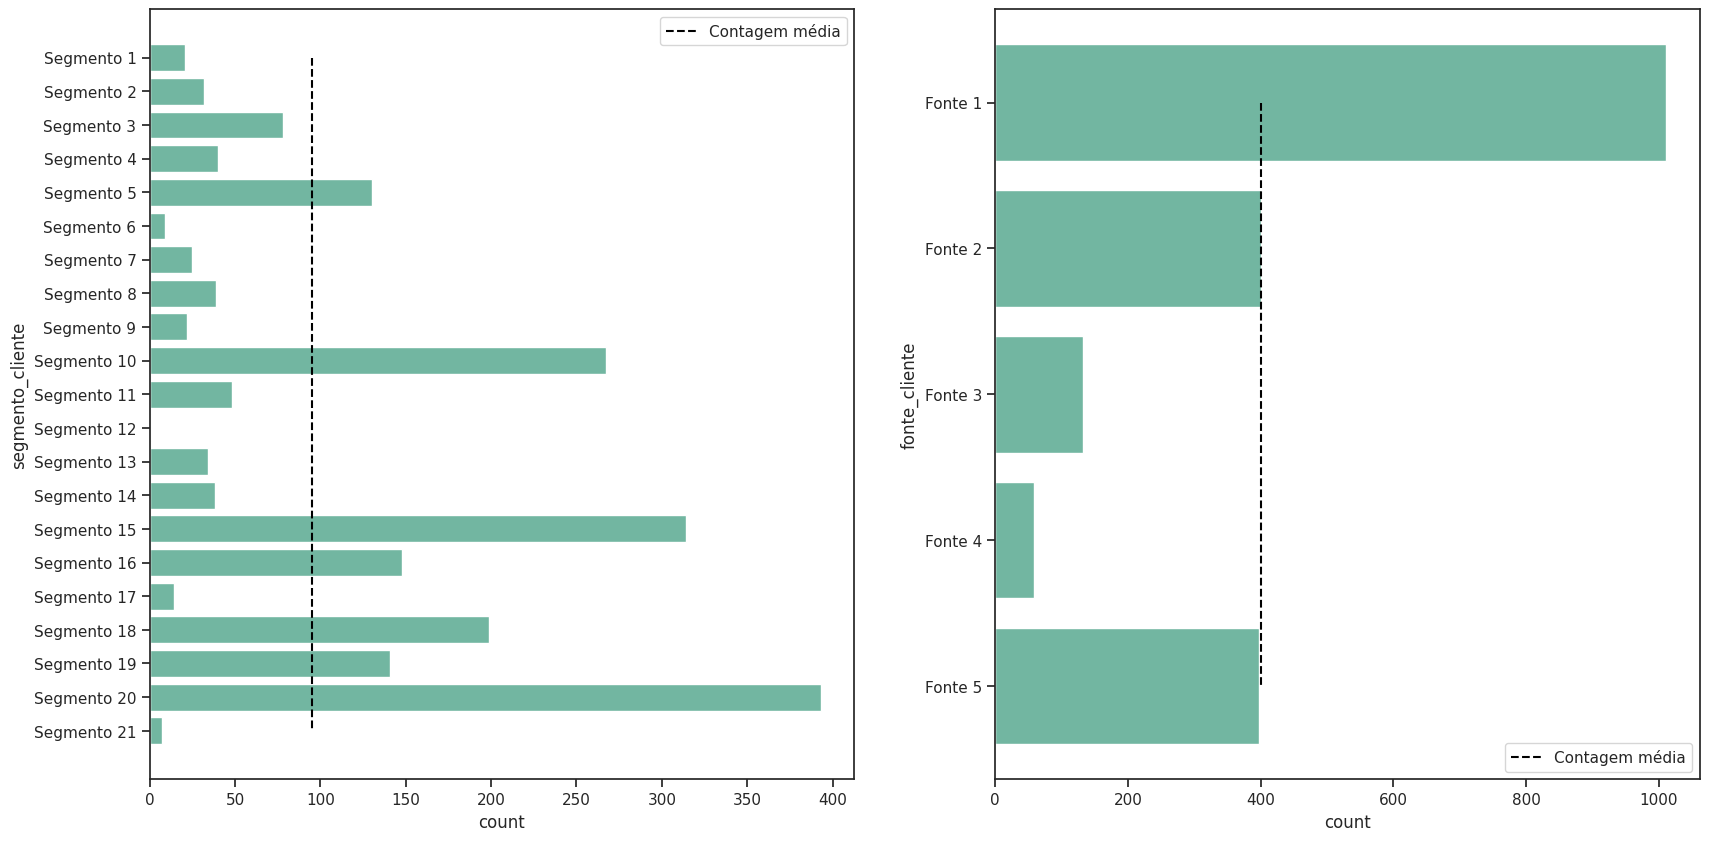

In [19]:
get_number = lambda str: str.split(' ')[1]
segmentos = leads.segmento_cliente.sort_values(key=lambda arr: [int(get_number(elem)) for elem in arr])
fontes = leads.fonte_cliente.sort_values(key=lambda arr: [int(get_number(elem)) for elem in arr])

ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

sb.countplot(data=segmentos, ax=ax1)
ax1.plot(
    [segmentos.value_counts().mean() for _ in segmentos.unique()],
    segmentos.unique(),
    linestyle='--',
    color='black',
)
ax1.legend(['Contagem média'])

sb.countplot(data=fontes, ax=ax2)
ax2.plot(
    [fontes.value_counts().mean() for _ in fontes.unique()],
    fontes.unique(),
    linestyle='--',
    color='black',
)
ax2.legend(['Contagem média'])

Em comparação com as variáveis de idade do CNPJ e de capital social, essas duas features apresentam muito mais variabilidade na contagem de suas categorias.

Os segmentos dos clientes são em sua grande maioria os 20, 15 e 10, com segmentos como o 12 tendo praticamente nenhuma amostra. Podemos agrupar alguns desses segmentos de baixa representatividade no futuro. Já a fonte do cliente é majoritariamente a 1, com as fontes 3 e 4 tendo baixíssima representatividade.

#### Natureza jurídica


<Axes: xlabel='count', ylabel='natureza_juridica'>

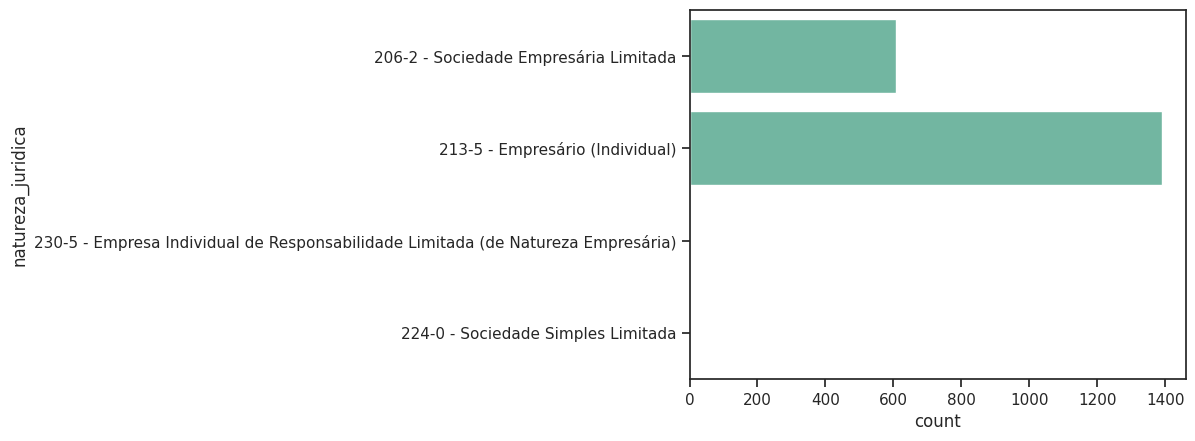

In [20]:
sb.countplot(data=leads.natureza_juridica)

A natureza jurídica apresenta uma variabilidade ainda maior: em geral, clientes são empresários individuais ou são parte de uma sociedade. Dessa forma, podemos agrupar as categorias `230-5` e `213-5`, e as categorias `206-2` e `224-0`, a partir dessa característica em comum para simplificar nosso trabalho durante o pré-processamento.

#### Faixa de preço no iFood

O atributo `ifood_faixa_preco` indica a faixa de preço dos estabelecimentos presentes no iFood, de `$` (mais barato) a `$$$$$` (mais caro). Por ser nulo para quem não está na plataforma, ele só existe para uma parcela dos leads.

<Axes: xlabel='count', ylabel='ifood_faixa_preco'>

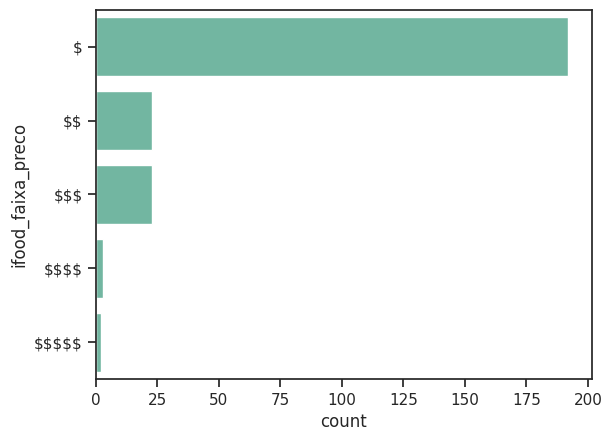

In [21]:
sb.countplot(data=leads.ifood_faixa_preco.dropna().sort_values().map(lambda str: str.replace('$', '\\$')))

Apenas cerca de 250 dos 2000 leads estão no iFood. Entre eles, a faixa `$` ocupa quase que a totalidade da amostra, `$$` e `$$$` cerca de 20 cada, e `$$$$` e `$$$$$` são próximas a 0. As faixas mais altas têm amostras pequenas demais para qualquer conclusão isolada.

#### Presença de website no Google Maps


<Axes: xlabel='google_maps_tem_website', ylabel='count'>

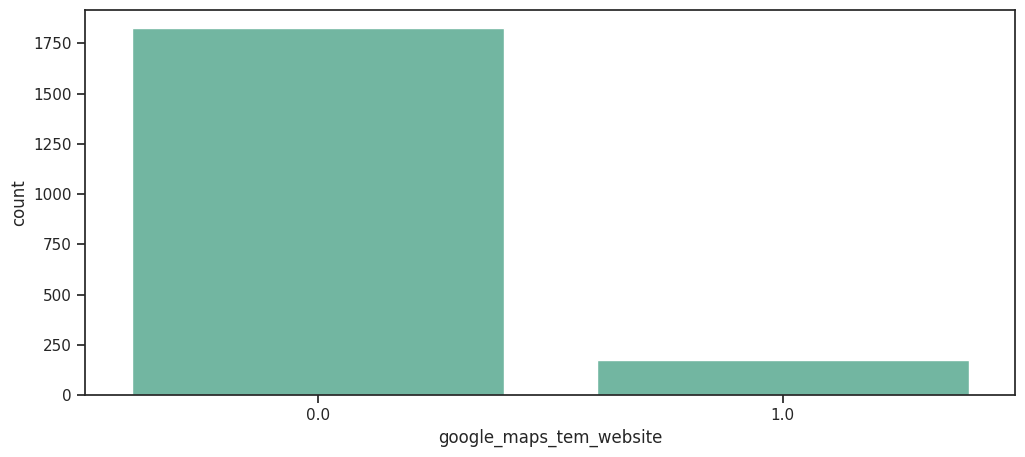

In [22]:
ax1 = plot.figure(figsize=(12, 5)).subplots(1, 1)

sb.countplot(x=leads.google_maps_tem_website.fillna(0), ax=ax1)


`google_maps_tem_website` é uma flag: uma pequena quantidade das leads têm valor (1), e os demais são nulos, que interpretamos como "não tem website". 

#### Município


In [23]:
def agrupa_raras(serie, minimo=30, nome='Outras'):
    contagem = serie.value_counts()
    return serie.where(serie.map(contagem) >= minimo, nome)

<Axes: xlabel='regiao', ylabel='count'>

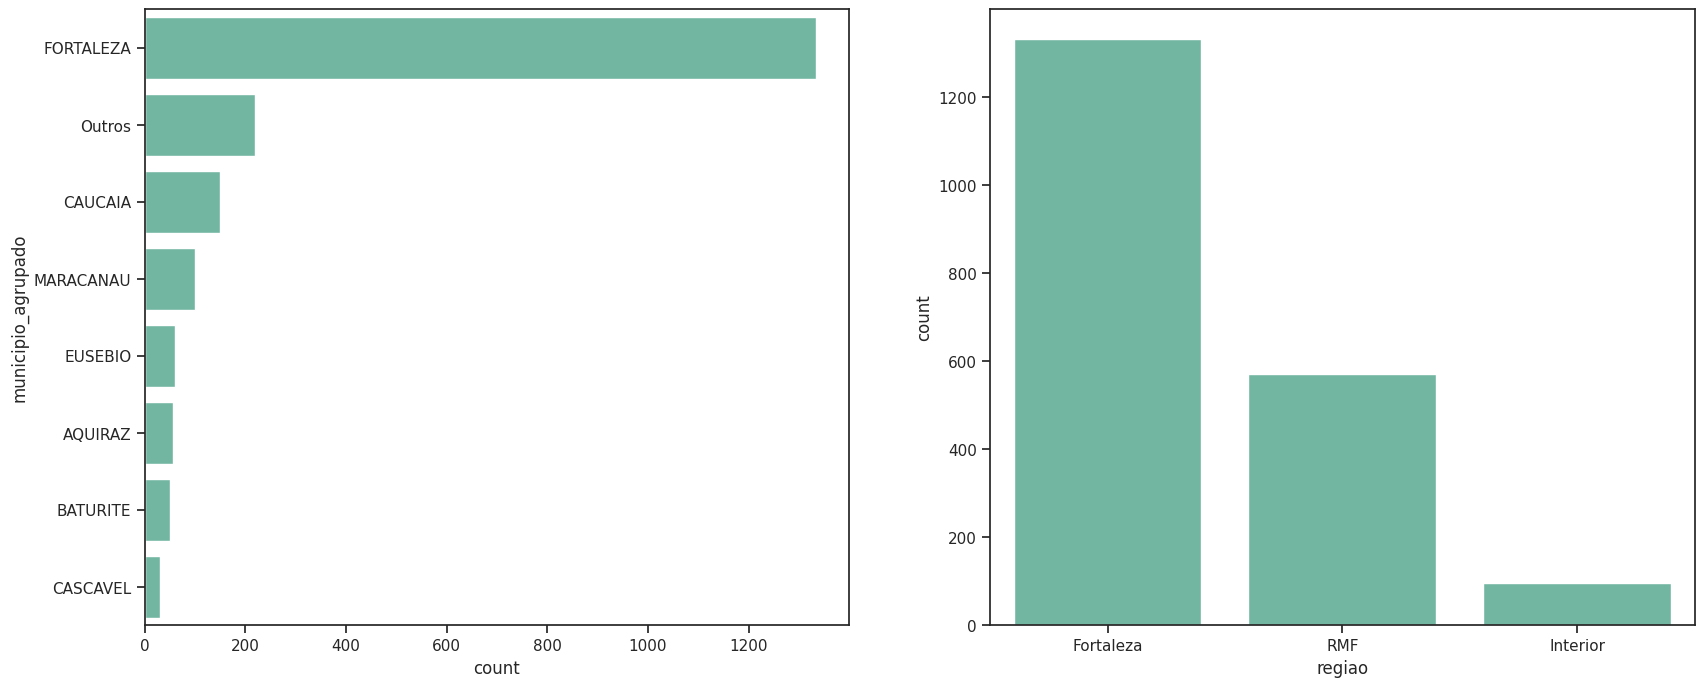

In [24]:
RMF = ['CAUCAIA', 'MARACANAU', 'MARANGUAPE', 'PACATUBA', 'ITAITINGA', 'EUSEBIO', 'AQUIRAZ', 'GUAIUBA', 'HORIZONTE',
       'PACAJUS', 'CHOROZINHO', 'SAO GONCALO DO AMARANTE', 'PINDORETAMA', 'CASCAVEL', 'PARACURU', 'PARAIPABA',
       'TRAIRI', 'SAO LUIS DO CURU']

leads['municipio_agrupado'] = agrupa_raras(leads['municipio'], nome='Outros')
leads['regiao'] = np.select([leads['municipio'] == 'FORTALEZA', leads['municipio'].isin(RMF)], ['Fortaleza', 'RMF'], 'Interior')

ax1, ax2 = plot.figure(figsize=(20, 8)).subplots(1, 2)
sb.countplot(data=leads, y='municipio_agrupado', order=leads.municipio_agrupado.value_counts().index, ax=ax1)
sb.countplot(data=leads, x='regiao', order=['Fortaleza', 'RMF', 'Interior'], ax=ax2)


`municipio` tem 31 valores distintos e é bastante concentrado: Fortaleza tem 1333 dos 2000 leads, a Região Metropolitana (RMF) 570 e o interior 97. Depois de Fortaleza, os maiores são Caucaia, Maracanaú, Eusébio, Aquiraz e Baturité. Os municípios com menos de 30 leads somam 220 e foram agrupados em "Outros". Um dos 31 valores não é um município (contém um nome de pessoa seguido de um número), o que indica erro de preenchimento a ser tratado no pré-processamento.

#### CNAE


O `CNAE` tem 107 códigos distintos, no formato AA.BC-C-DD (divisão > grupo > classe > subclasse). Os códigos foram anonimizados: alguns, como 12.10-3-97, não existem no CNAE 2.3 do IBGE, então os valores não têm significado explícito. Confirmamos com a monitoria que a troca é consistente (toda divisão igual vira o mesmo número), portanto a hierarquia continua válida.

exemplos de alguns códigos: ['12.10-3-97', '12.74-7-12', '12.74-7-32', '12.74-7-79', '14.17-3-90']


,categorias,categorias com >= 30 leads,leads nessas categorias
cnae_divisao,27,4,1909
cnae_grupo,60,7,1774
cnae_classe,77,7,1749
cnae_subclasse,107,13,1717


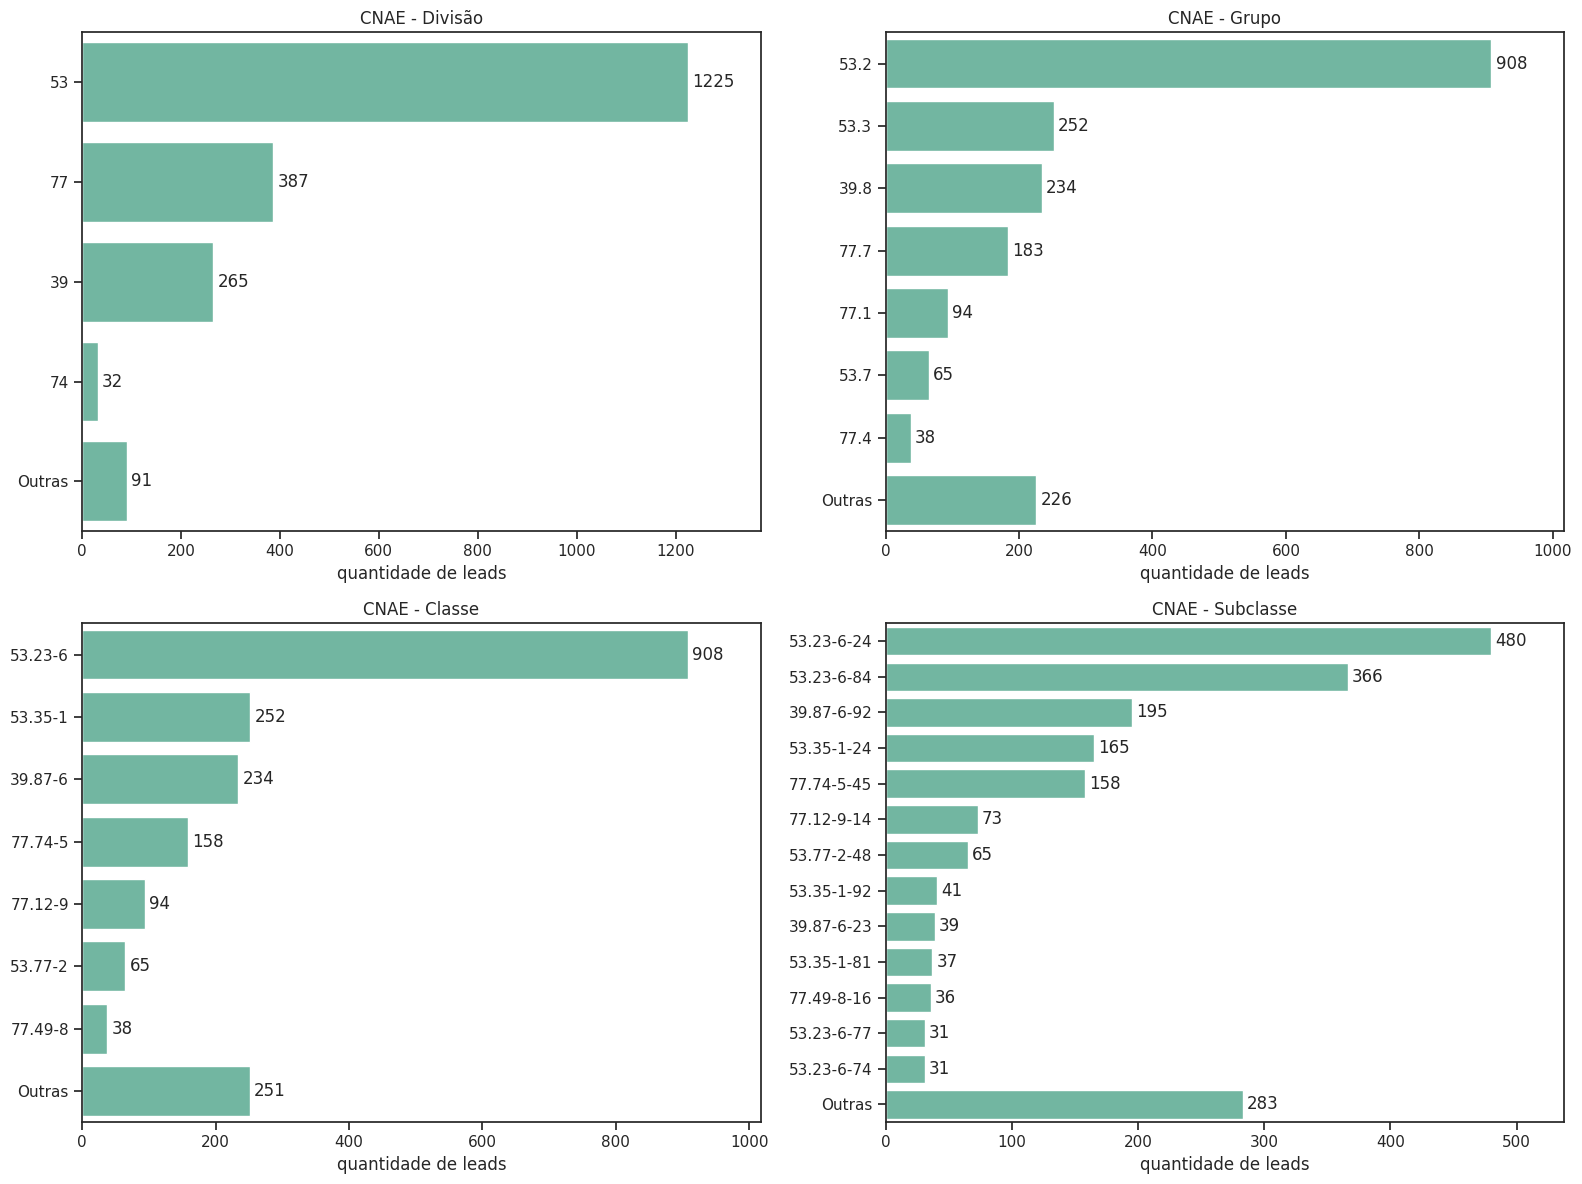

In [25]:
# hierarquia do CNAE no estilo do dataset:
# AA -> divisão | AA.B -> grupo | AA.BC-C -> classe | AA.BC-C-DD -> subclasse
leads['cnae_divisao'] = leads['cnae_codigo'].str[:2]
leads['cnae_grupo'] = leads['cnae_codigo'].str[:4]
leads['cnae_classe'] = leads['cnae_codigo'].str[:7]
leads['cnae_subclasse'] = leads['cnae_codigo']

print(f'exemplos de alguns códigos: {sorted(leads.cnae_codigo)[:5]}')

# quantas categorias existem em cada nível, e quantas têm pelo menos 30 leads
niveis = ['cnae_divisao', 'cnae_grupo', 'cnae_classe', 'cnae_subclasse']
titulos = ['Divisão', 'Grupo', 'Classe', 'Subclasse']
display(pd.DataFrame({
    'categorias': [leads[n].nunique() for n in niveis],
    'categorias com >= 30 leads': [(leads[n].value_counts() >= 30).sum() for n in niveis],
    'leads nessas categorias': [leads[n].map(leads[n].value_counts()).ge(30).sum() for n in niveis],
}, index=niveis))

axes = plot.figure(figsize=(16, 12)).subplots(2, 2)
for ax, nivel, titulo in zip(axes.flat, niveis, titulos):
    agrupado = agrupa_raras(leads[nivel])  # categorias com menos de 30 leads viram 'Outras'
    ordem = [c for c in agrupado.value_counts().index if c != 'Outras'] + ['Outras']

    sb.countplot(y=agrupado, order=ordem, ax=ax)
    ax.bar_label(ax.containers[0], padding=3)
    ax.margins(x=0.12)
    ax.set_title(f'CNAE - {titulo}')
    ax.set_xlabel('quantidade de leads')
    ax.set_ylabel('')
plot.tight_layout()

A distribuição é muito concentrada: a divisão 53 reúne 1225 dos 2000 leads, e as divisões 53, 77 (387) e 39 (265) somam 1877. Apenas 4 das 27 divisões têm pelo menos 30 leads. No grupo e na classe, a categoria mais frequente (53.2 e 53.23-6) concentra 908 leads. Conforme descemos na hierarquia, os dados se fragmentam: só 13 das 107 subclasses têm pelo menos 30 leads, e a quantidade de leads agrupados em "Outras" cresce de 91 (divisão) para 283 (subclasse).

#### Atributos do Serasa


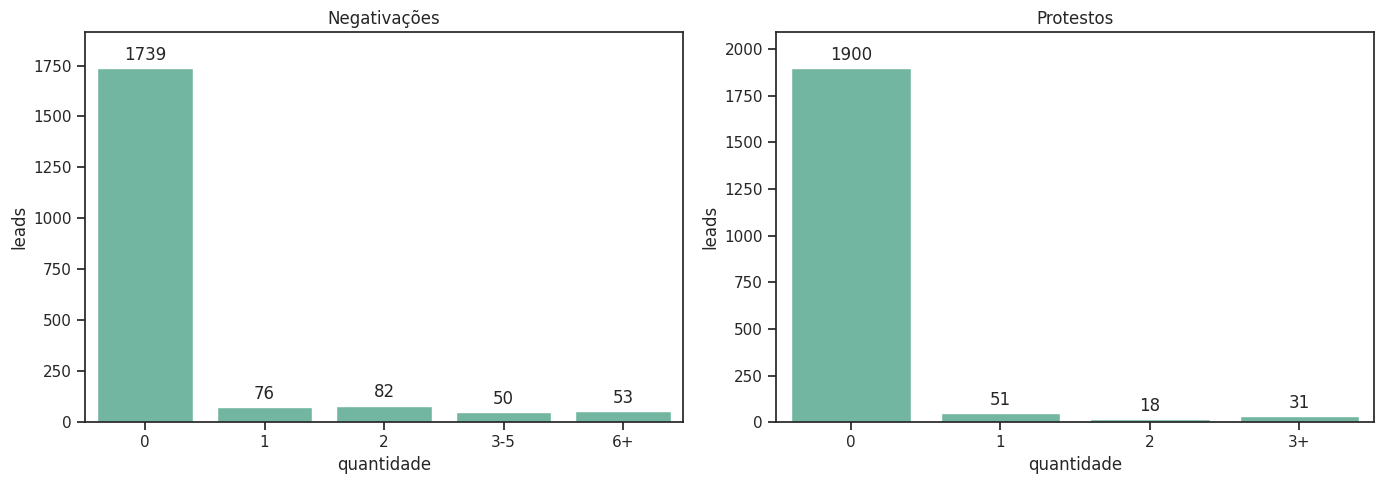

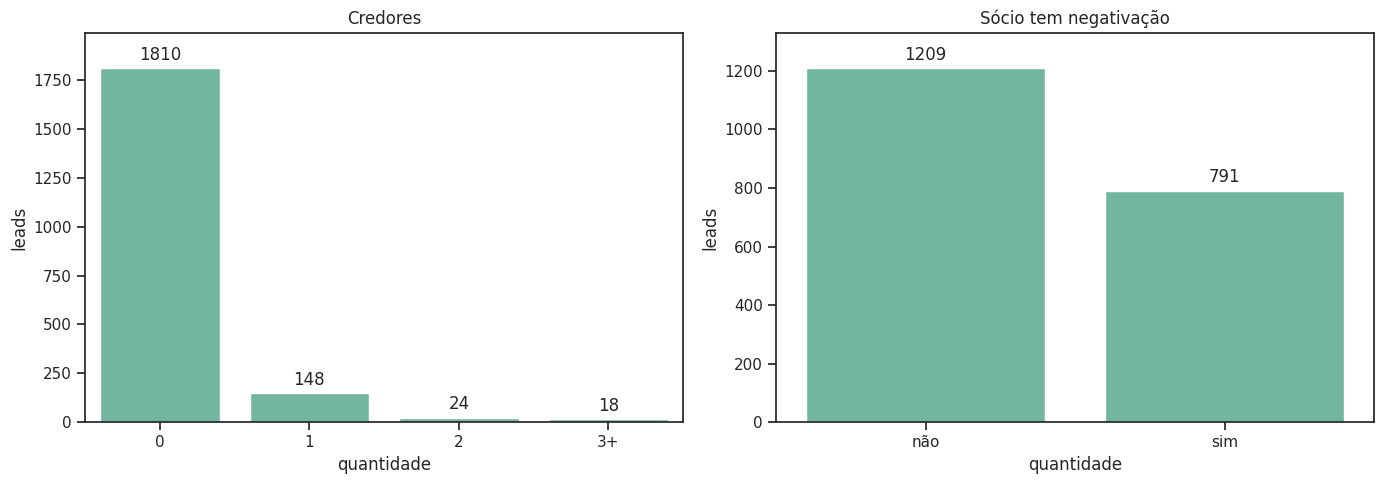

In [26]:
leads['qtd_credores'] = leads['serasa_credores'].str.split(', ').str.len().fillna(0).astype(int)

# a cauda é agrupada em poucas faixas - os valores altos são raros
leads['faixa_negativacoes'] = pd.cut(leads['serasa_contagem_negativacoes'], [-1, 0, 1, 2, 5, np.inf], labels=['0', '1', '2', '3-5', '6+'])
leads['faixa_protestos'] = pd.cut(leads['serasa_contagem_protestos'], [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
leads['faixa_credores'] = pd.cut(leads['qtd_credores'], [-1, 0, 1, 2, np.inf], labels=['0', '1', '2', '3+'])
leads['socio_negativado'] = leads['serasa_socio_tem_negativacao'].map({0: 'não', 1: 'sim'})

def plota_dois(colunas, titulos):
    axes = plot.figure(figsize=(14, 5)).subplots(1, 2)
    for ax, coluna, titulo in zip(axes, colunas, titulos):
        sb.countplot(data=leads, x=coluna, ax=ax)
        ax.bar_label(ax.containers[0], padding=3)
        ax.margins(y=0.1)
        ax.set_title(titulo)
        ax.set_xlabel('quantidade')
        ax.set_ylabel('leads')
    plot.tight_layout()

plota_dois(['faixa_negativacoes', 'faixa_protestos'], ['Negativações', 'Protestos'])
plota_dois(['faixa_credores', 'socio_negativado'], ['Credores', 'Sócio tem negativação'])


Em todos eles o padrão é o mesmo: a grande maioria dos leads não tem nada registrado, e poucos concentram os valores altos. Isso significa que, sozinhas, essas variáveis têm pouca variabilidade e só distinguem um grupo pequeno de leads. Se houver impacto no churn, ele vem provavelmente de o lead estar ou não nesse grupo, e menos da magnitude. Além disso, os poucos valores muito altos podem distorcer qualquer análise que trate a contagem como uma escala numérica.

### 2.2 Comportamento de pedidos

Agora analisamos a distribuição dos atributos da tabela de **pedidos**, que descrevem o comportamento de compra dos clientes.


#### Valor e quantidade de produtos por pedido


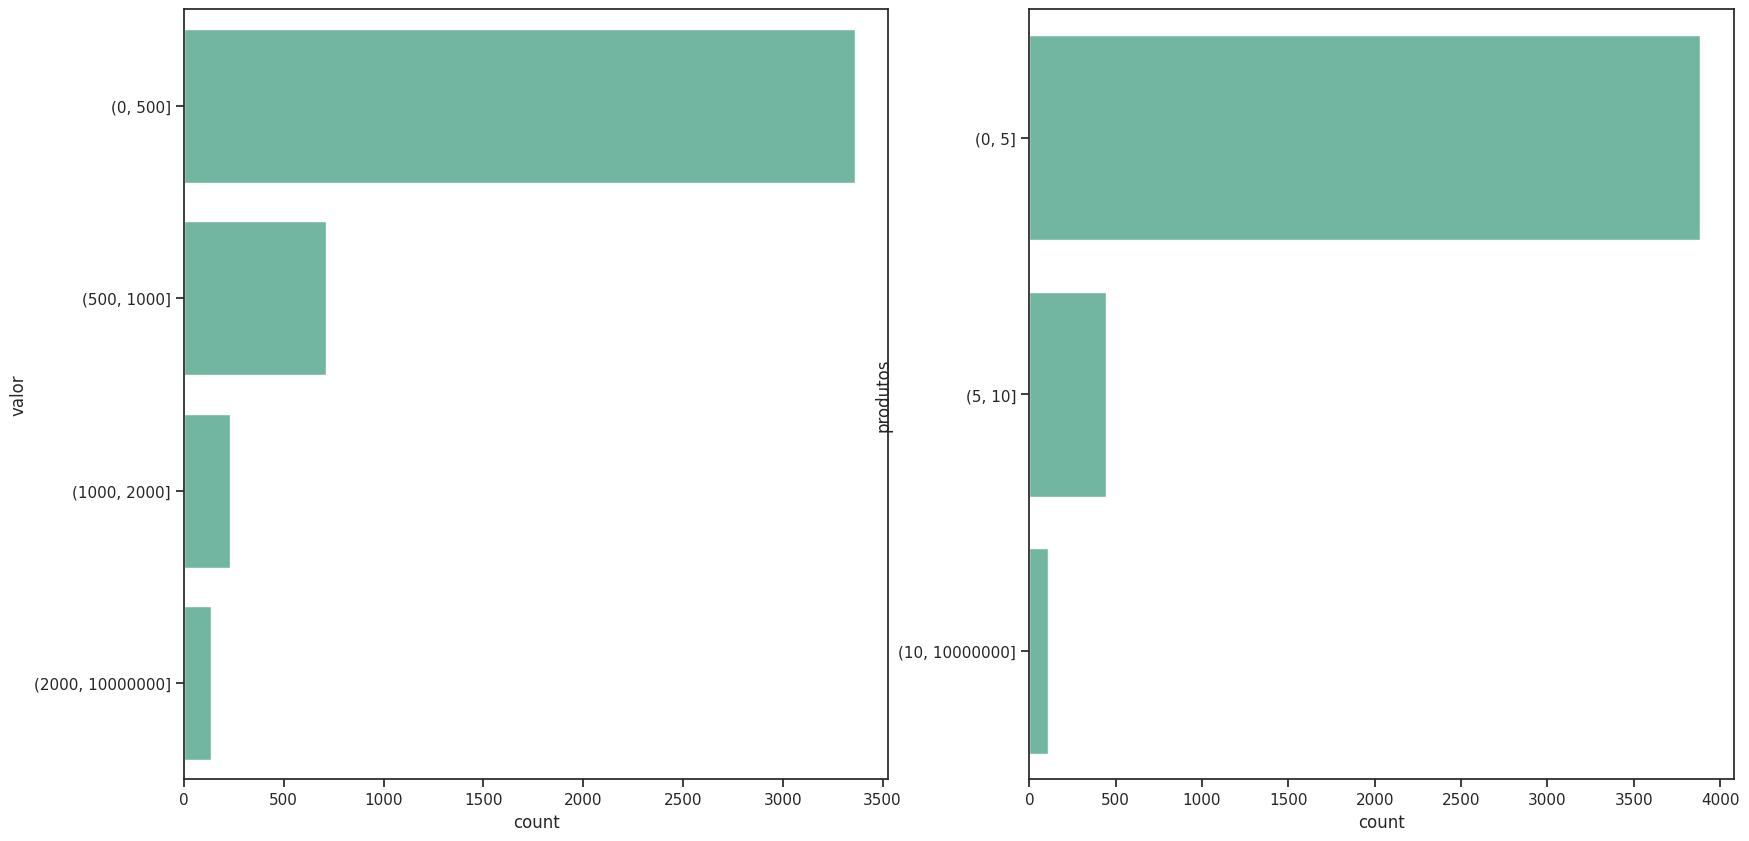

In [27]:
plot_ranged_countplot1x2(pedidos, ('valor', 'produtos'))

Isso nos deu um bom insight para o comportamento geral dos clientes registrados: os clientes da Praso tendem a comprar muitos produtos relativamente baratos e compram em baixa quantidade:

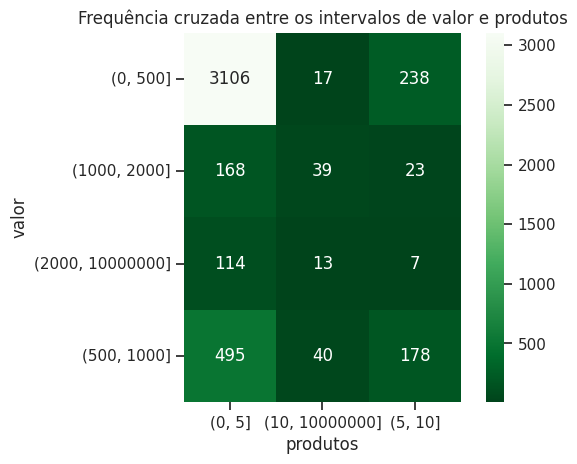

In [28]:
plot.title('Frequência cruzada entre os intervalos de valor e produtos')
_ = sb.heatmap(pd.crosstab(pedidos.valor, pedidos.produtos), annot=True, fmt='', square=True, cmap='Greens_r')


Nós tínhamos a impressão de que o valor de cada pedido estaria no intervalo mais baixo, mas que haveria uma quantidade maior de produtos comprados, seguindo o princípio da [curva ABC de produtos](https://www.cbsistemas.com.br/curva-abc-de-produtos-o-que-e-e-por-que-ela-e-tao-importante/), o qual nos foi introduzido durante a aula de conversa com um funcionário da Praso.

#### Data de entrega


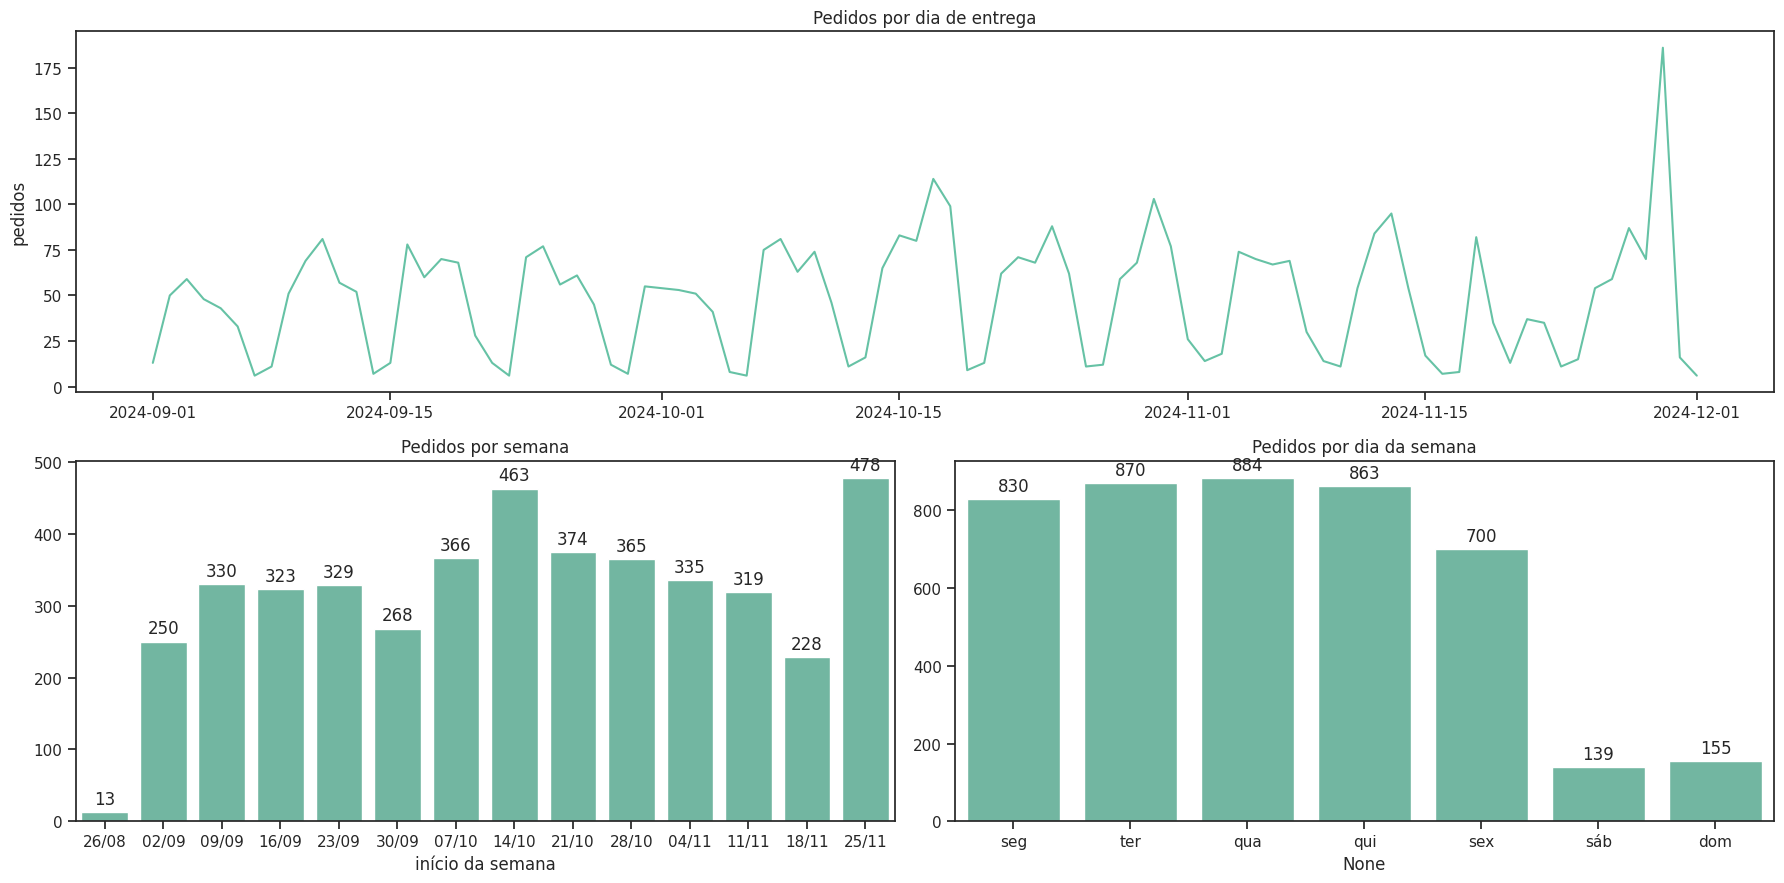

In [29]:
datas = pd.to_datetime(pedidos.data_entrega)

por_dia = datas.value_counts().sort_index().asfreq('D', fill_value=0)  # dias sem pedido contam como 0
por_semana = datas.dt.to_period('W').value_counts().sort_index()
por_dia_da_semana = datas.dt.dayofweek.value_counts().sort_index()
por_dia_da_semana.index = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']

fig, axes = plot.subplot_mosaic([['dia', 'dia'], ['semana', 'dia_semana']], figsize=(18, 9))

axes['dia'].plot(por_dia.index, por_dia.values)
axes['dia'].set_title('Pedidos por dia de entrega')
axes['dia'].set_ylabel('pedidos')

sb.barplot(x=por_semana.index.start_time.strftime('%d/%m'), y=por_semana.values, ax=axes['semana'])
axes['semana'].bar_label(axes['semana'].containers[0], padding=3)
axes['semana'].set_title('Pedidos por semana')
axes['semana'].set_xlabel('início da semana')

sb.barplot(x=por_dia_da_semana.index, y=por_dia_da_semana.values, ax=axes['dia_semana'])
axes['dia_semana'].bar_label(axes['dia_semana'].containers[0], padding=3)
axes['dia_semana'].set_title('Pedidos por dia da semana')

plot.tight_layout()


A entrega de pedidos tem uma sazonalidade semanal forte: o volume é alto de segunda a sexta e cai bastante no sábado e no domingo, o que é típico de um fornecedor que atende comércios. Fora esse padrão, o volume ao longo do trimestre é relativamente estável, sem tendência clara de crescimento ou queda. O maior pico do período está no último dia útil de novembro (29/11), que coincide com a Black Friday de 2024.

---


## 3. Análise bivariada


Vamos agora relacionar os atributos dos leads com o `churned`


### 3.1 Perfil dos leads


#### Fonte e segmento do cliente


<Axes: xlabel='count', ylabel='segmento_cliente'>

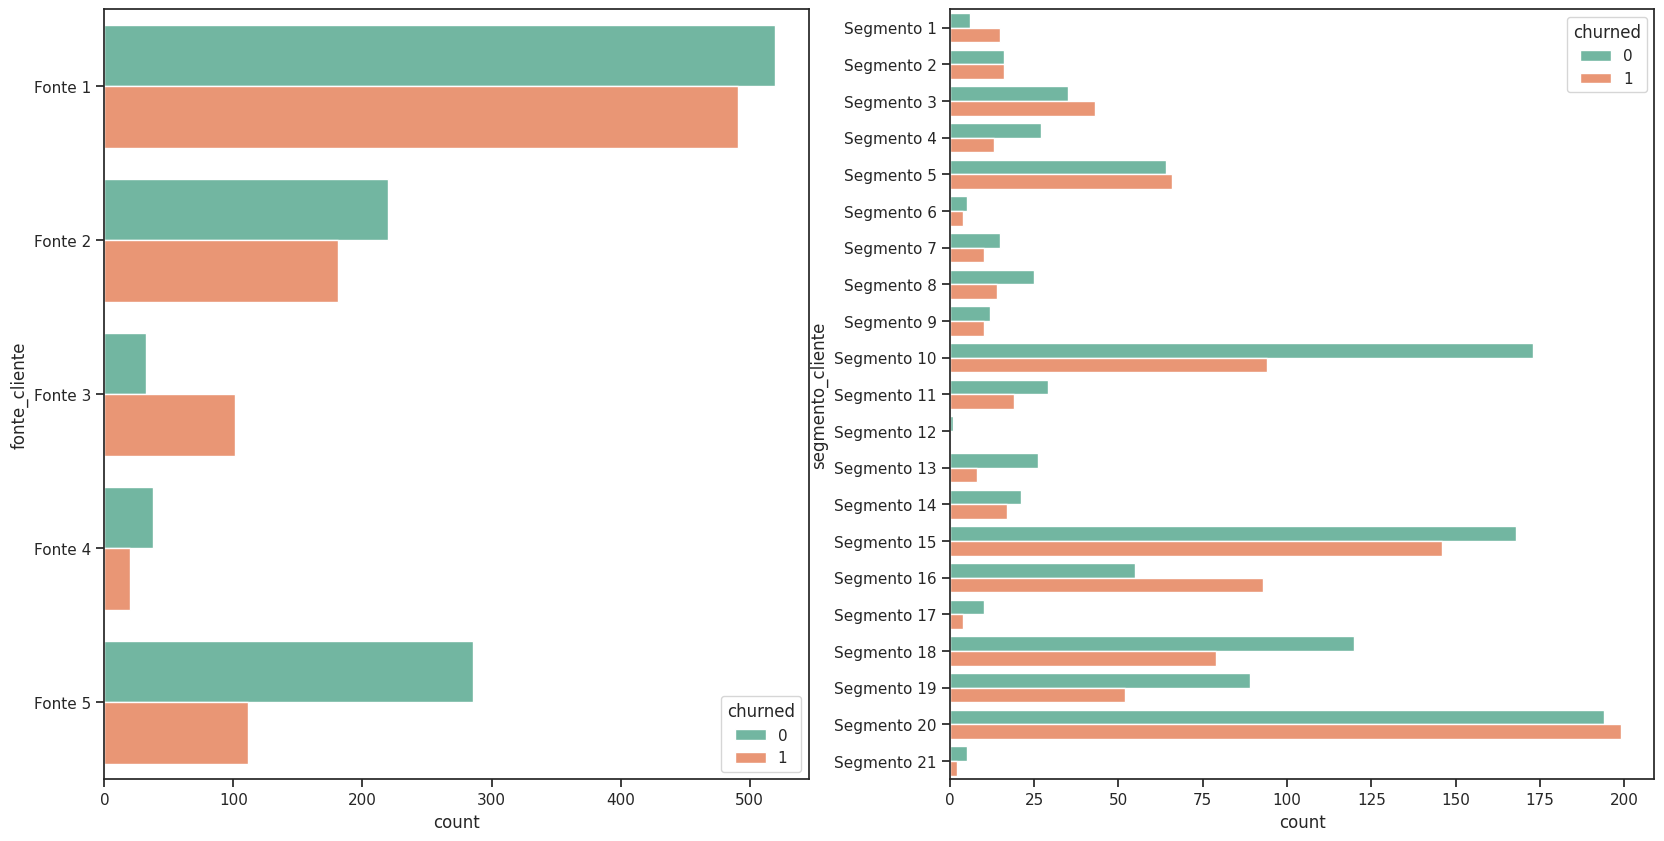

In [30]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)
sb.countplot(data=leads, hue='churned', y='fonte_cliente', order=fontes, ax=ax1)
sb.countplot(data=leads, hue='churned', y='segmento_cliente', order=segmentos, ax=ax2)

Fonte e segmento são rótulos anonimizados; o número é só um identificador, sem ordem. O teste qui-quadrado indica relação com o churn nos dois atributos (p ≈ 0,0000).

Fonte: a Fonte 3 (133 clientes) tem churn de 75,9%, muito acima das demais, e a Fonte 5 (397) tem o menor, 28,0%. As Fontes 1 (1011) e 2 (401) ficam em 48,6% e 45,1%, e a Fonte 4 (58) em 34,5%.
Segmento: o Segmento 16 (148 clientes) tem o maior churn entre os que têm amostra razoável, 62,8%, e o 13 (34) tem o menor, 23,5%. No gráfico, os Segmentos 10, 18 e 19 têm mais retidos que churned, e os Segmentos 16 e 3 têm o inverso.
Os Segmentos 1, 6, 7, 9, 12, 17 e 21 têm menos de 30 clientes cada (de 1 a 25). Suas taxas não são confiáveis e foram agrupadas em "Outras" na análise.

#### Negativações e credores no Serasa

Text(0.5, 1.0, 'Contagem de amostras em relação ao churn (para referência)')

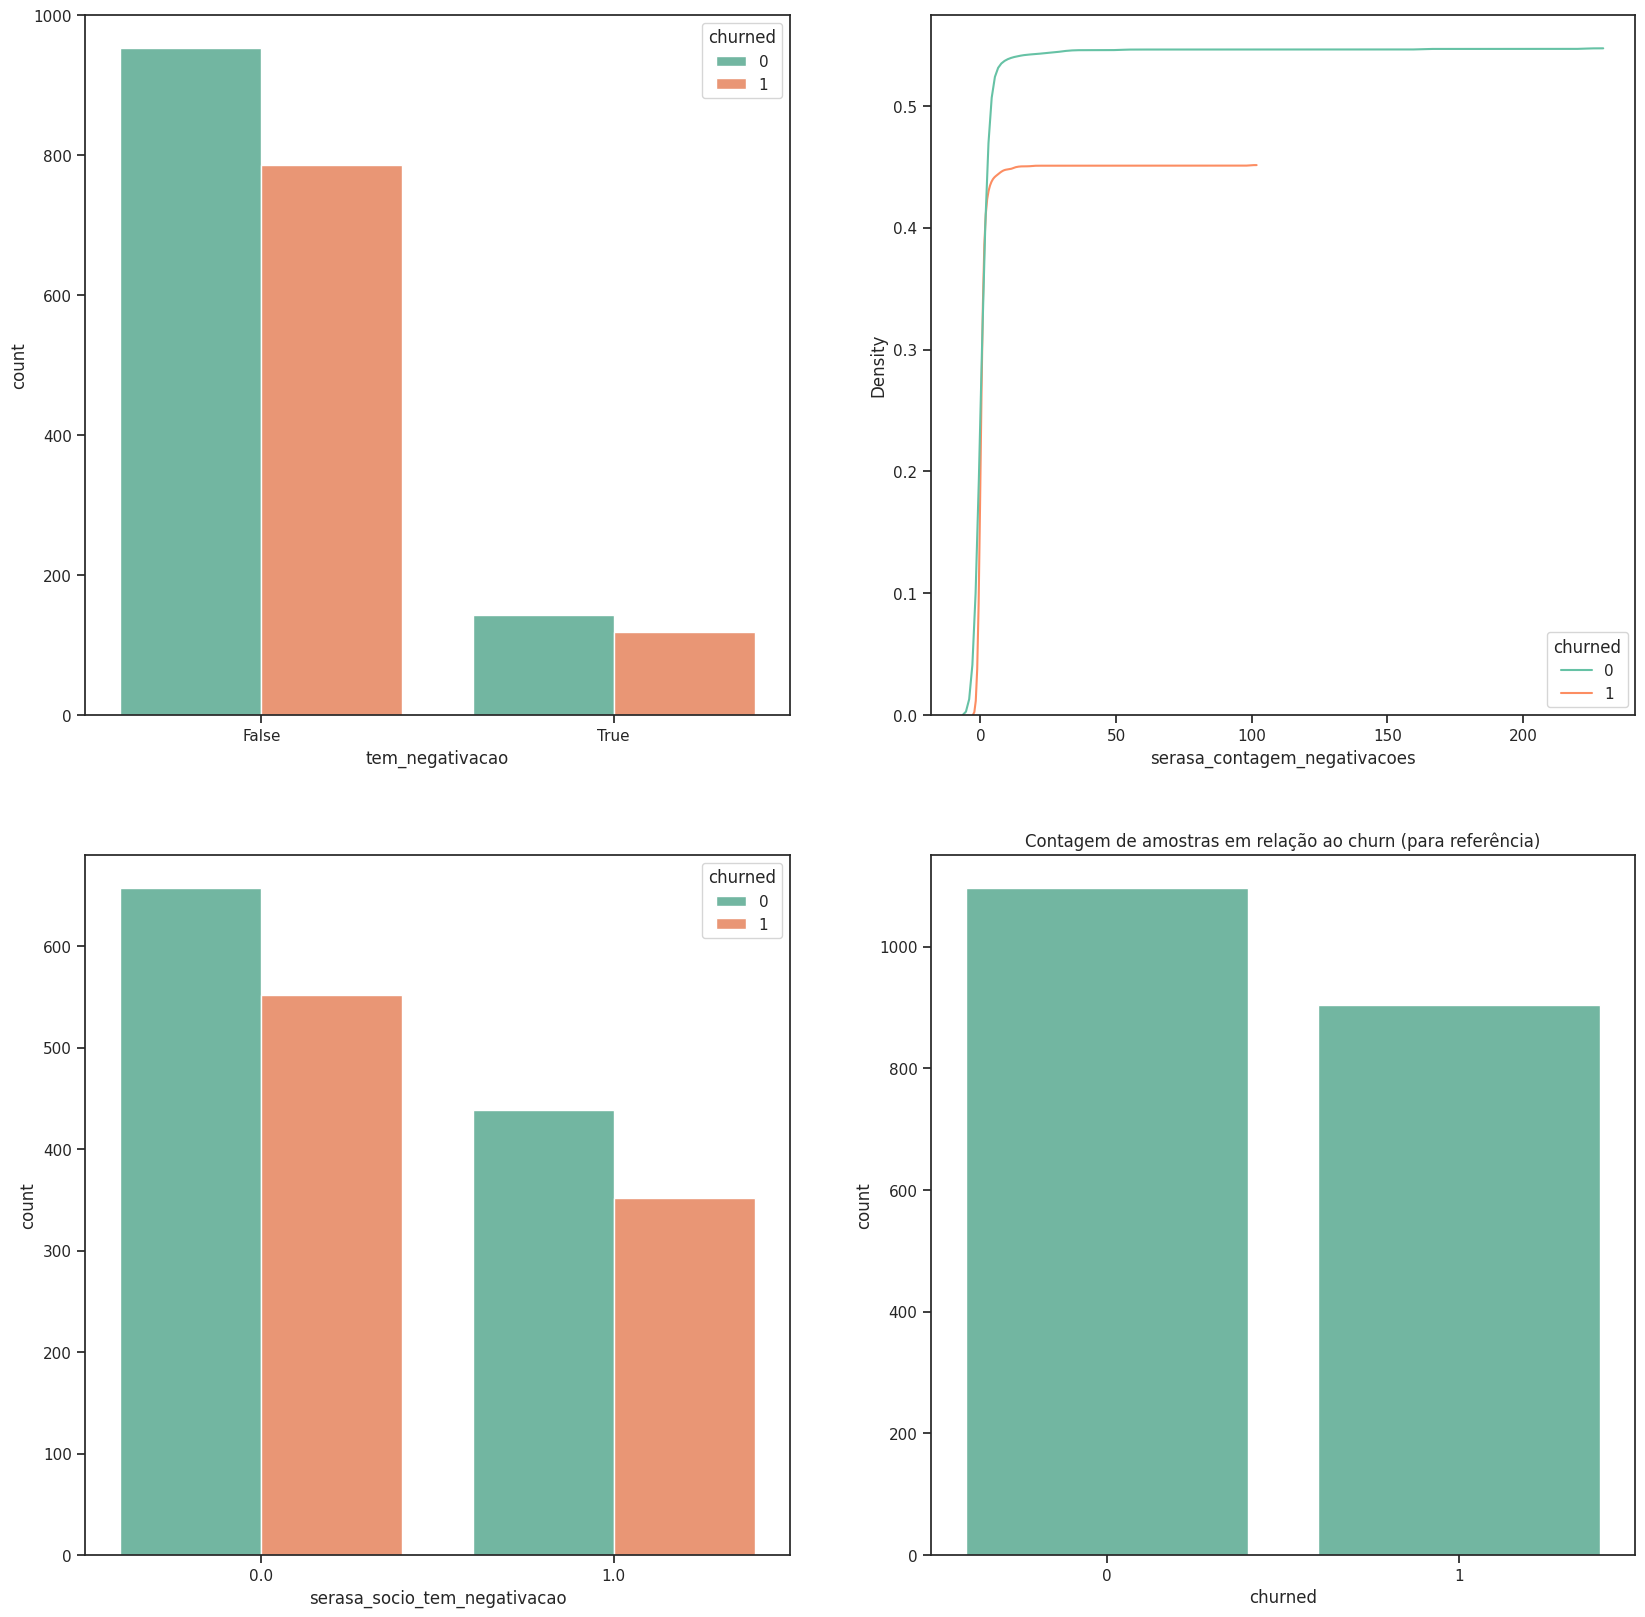

In [31]:
(ax1, ax2), (ax3, ax4) = plot.figure(figsize=(20, 20)).subplots(2, 2)

leads['tem_negativacao'] = leads.serasa_contagem_negativacoes > 0

sb.countplot(data=leads, x='tem_negativacao', hue='churned', ax=ax1)
sb.kdeplot(data=leads, x='serasa_contagem_negativacoes', hue='churned', ax=ax2, cumulative=True)

sb.countplot(data=leads, x='serasa_socio_tem_negativacao', hue='churned', ax=ax3)
sb.countplot(data=leads, x='churned', ax=ax4)
ax4.set_title('Contagem de amostras em relação ao churn (para referência)')

no geral, as duas variáveis seguem o mesmo padrão do gráfico de referência: a maioria dos clientes não dá churn, com ou sem negativação. Tanto em tem_negativacao quanto em serasa_socio_tem_negativacao, a proporção entre quem dá e quem não dá churn quase não muda entre as categorias,ou seja, ter negativação (própria ou do sócio) não parece fazer muita diferença pro churn

**Quantidade de credores:**

<Axes: xlabel='faixa_credores', ylabel='count'>

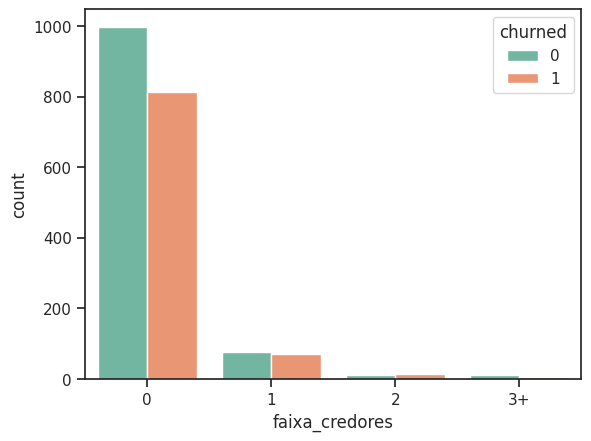

In [32]:
sb.countplot(data=leads, x='faixa_credores', hue='churned')

a taxa de churn não muda muito com a quantidade de credores (fica entre 39% e 54%), e os grupos com 2 ou 3+ credores têm poucas amostras (24 e 18 leads), então não dá pra confiar muito numa tendência aí.

**Tipos de credor:**

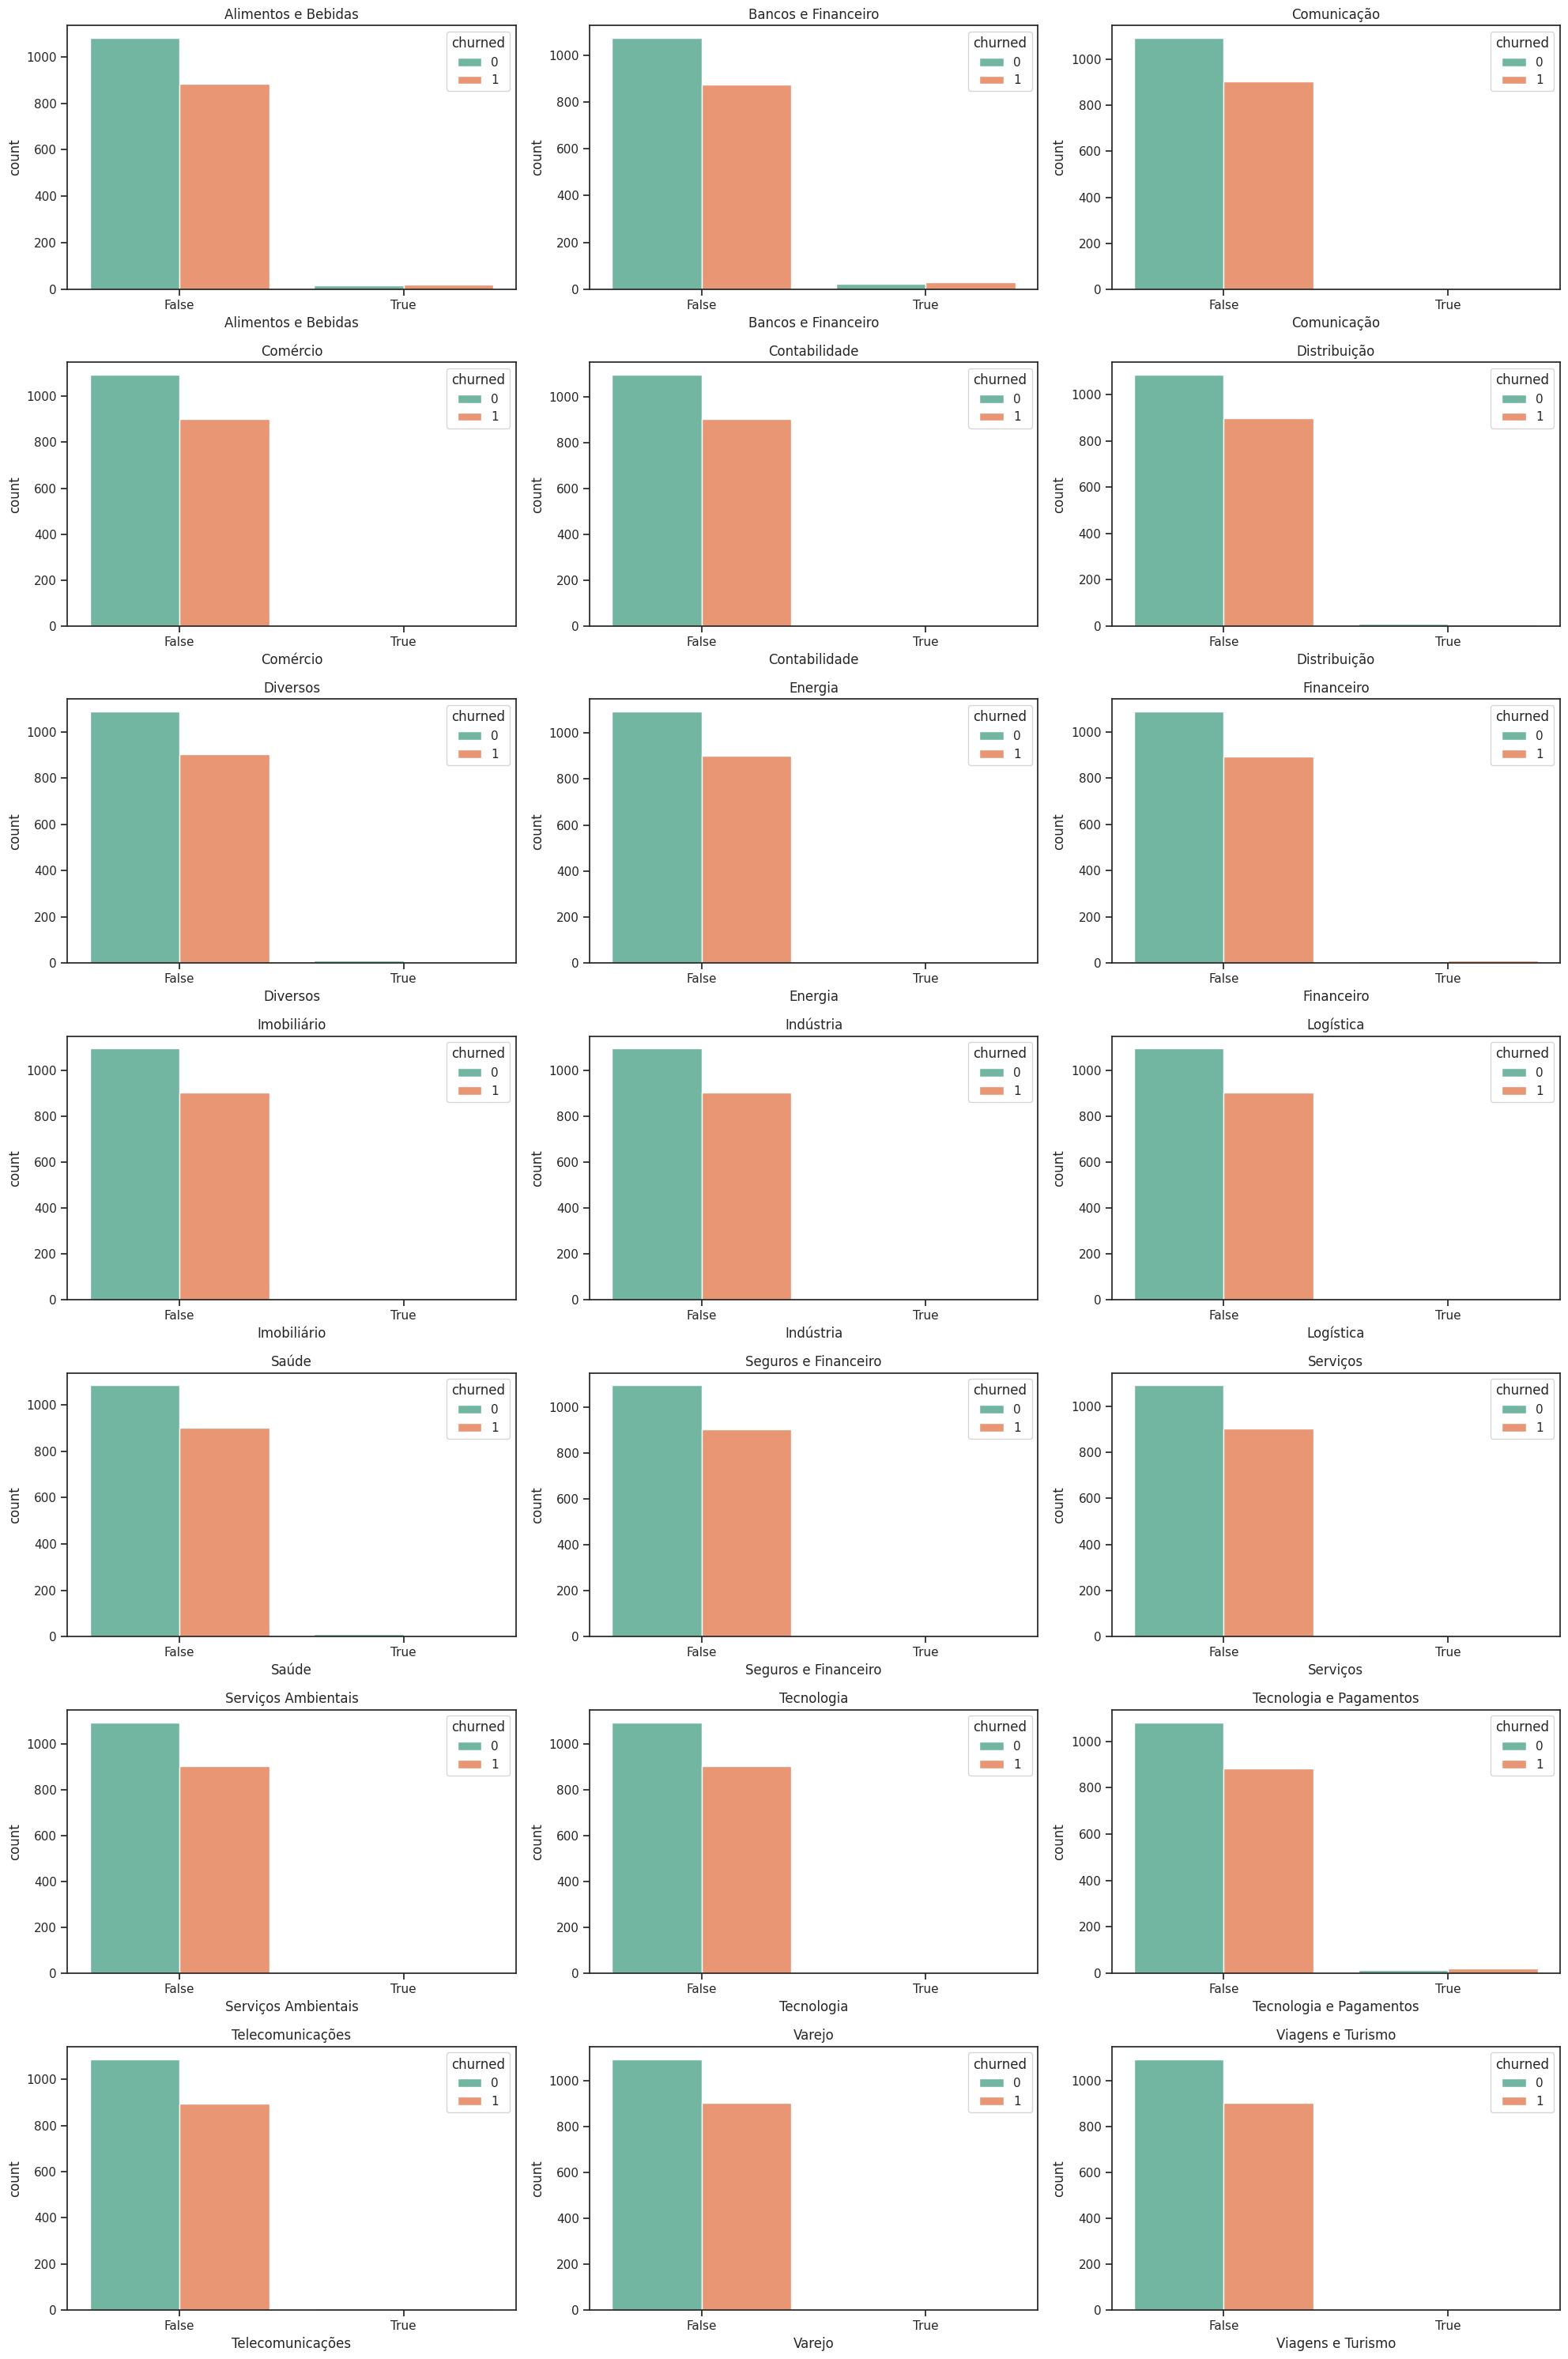

In [33]:
credores: set[str] = set()
for credor in leads.serasa_credores.dropna().unique():
    credores.update(credor.split(', '))

axes = plot.figure(figsize=(20, 30)).subplots(7, 3)
for i, tipo_credor in enumerate(sorted(credores)):
    ax = axes[i // 3][i % 3]
    leads[tipo_credor] = leads.serasa_credores.apply(lambda obj: tipo_credor in obj.split(', ') if isinstance(obj, str) else False)
    sb.countplot(data=leads, x=tipo_credor, hue='churned', ax=ax)
    ax.set_title(tipo_credor)
plot.tight_layout()

a maioria dos tipos de credor tem pouquíssimas amostras (vários com menos de 10 leads, alguns com só 1), então a taxa de churn de cada tipo isolado não é confiável. chegamos a pensar em separar `Tecnologia e Pagamentos` em duas categorias, mas como já são só 34 leads nessa categoria, dividir ia deixar as duas partes ainda menores e a gente ia perder a relação entre elas. além disso, olhando os tipos com mais amostra, a taxa de churn fica numa faixa parecida (perto de 50%), sem nenhum se destacar muito, então não parece valer a pena detalhar mais os tipos de credor.

#### CNAE

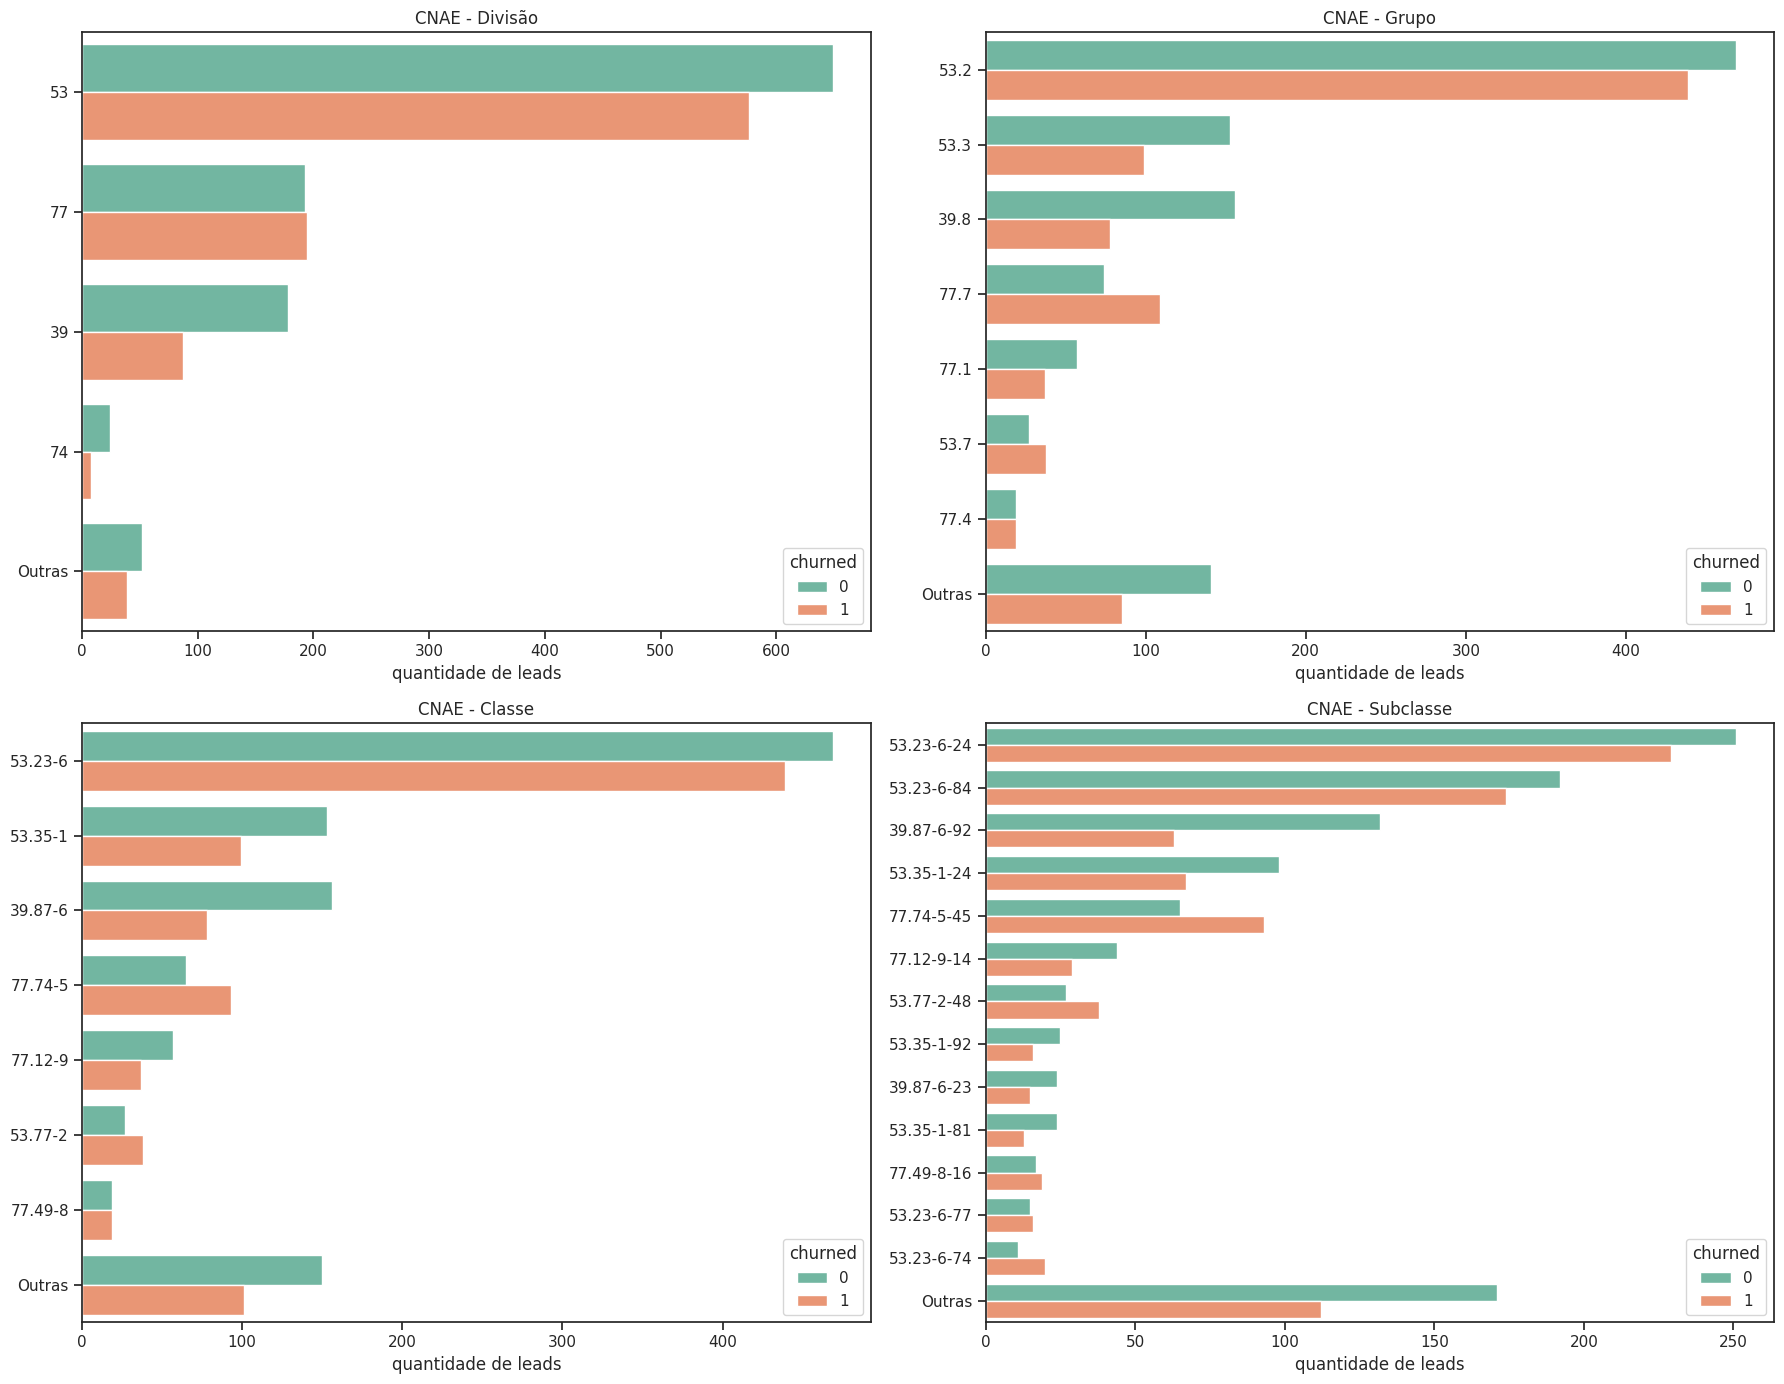

In [34]:
# niveis e titulos já foram definidos na análise univariada do CNAE (seção 2.1)
axes = plot.figure(figsize=(18, 14)).subplots(2, 2)
for ax, nivel, titulo in zip(axes.flat, niveis, titulos):
    agrupado = agrupa_raras(leads[nivel])  # categorias com menos de 30 leads viram 'Outras'
    ordem = [c for c in agrupado.value_counts().index if c != 'Outras'] + ['Outras']

    sb.countplot(data=leads, y=agrupado, hue=leads.churned, order=ordem, ax=ax)
    ax.set_title(f'CNAE - {titulo}')
    ax.set_xlabel('quantidade de leads')
    ax.set_ylabel('')
plot.tight_layout()

a divisão 39 chama atenção por ter uma taxa de churn visivelmente mais baixa que as outras, e esse padrão se repete nos grupos, classes e subclasses que vêm dela. Só que, conforme a gente desce na hierarquia, sobra cada vez menos lead por categoria,a maioria vira "Outras" por ter poucos dados, igual já tínhamos visto na univariada. Como o padrão de churn por divisão já aparece nos níveis mais fundos, não parece valer a pena olhar além da divisão.

#### CNAE × Segmento

<Axes: title={'center': 'Distribuição das divisões de CNAE dentro de cada segmento'}, xlabel='cnae_divisao', ylabel='segmento_cliente'>

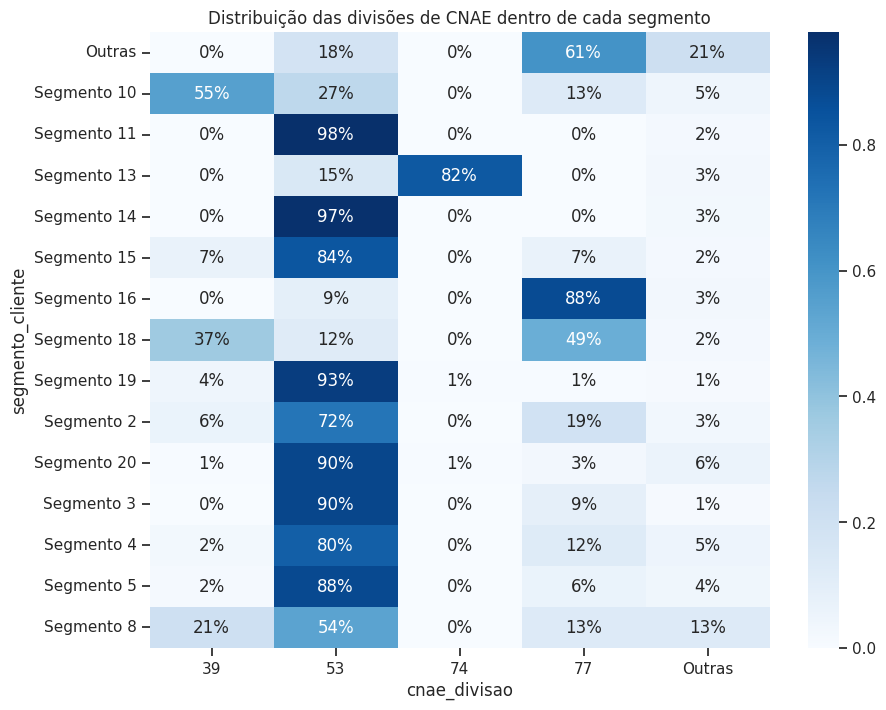

In [35]:
seg = agrupa_raras(leads['segmento_cliente'])
cnae = agrupa_raras(leads['cnae_divisao'])

proporcao = pd.crosstab(seg, cnae, normalize='index')

plot.figure(figsize=(10, 8))
plot.title('Distribuição das divisões de CNAE dentro de cada segmento')
sb.heatmap(proporcao, annot=True, fmt='.0%', cmap='Blues')

dá pra ver que o segmento praticamente determina a divisão do CNAE: a maioria dos segmentos está concentrada numa única divisão. o caminho contrário não é tão forte assim, uma mesma divisão aparece espalhada em vários segmentos. isso sugere que `segmento_cliente` carrega mais informação que `cnae_divisao` sozinho. conversamos com o professor sobre essa correlação forte entre os dois atributos, e ele sugeriu que a gente descarte o CNAE também, já que o segmento cobre boa parte dessa informação.

#### Região e município

<Axes: xlabel='regiao', ylabel='count'>

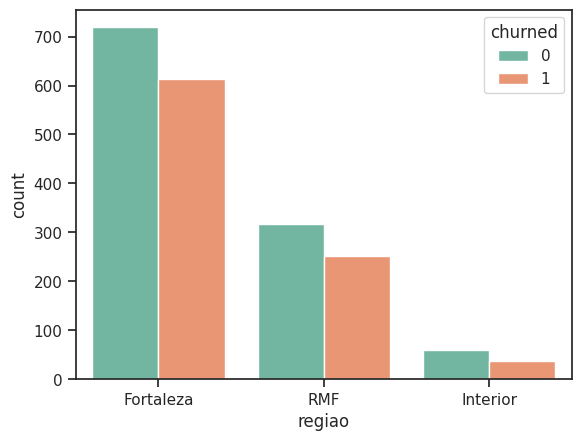

In [36]:
sb.countplot(data=leads, x='regiao', hue='churned', order=['Fortaleza', 'RMF', 'Interior'])

município sozinho é muito específico pra olhar direto, são 31 valores, boa parte com poucas dezenas de leads, então faz mais sentido comparar pela região (Fortaleza / RMF / interior), que já é uma visão mais estável. a taxa de churn fica bem parecida nas três

#### Presença no iFood


<Axes: title={'center': 'Tabela de frequência entre tem_ifood e churn'}, xlabel='churned', ylabel='tem_ifood'>

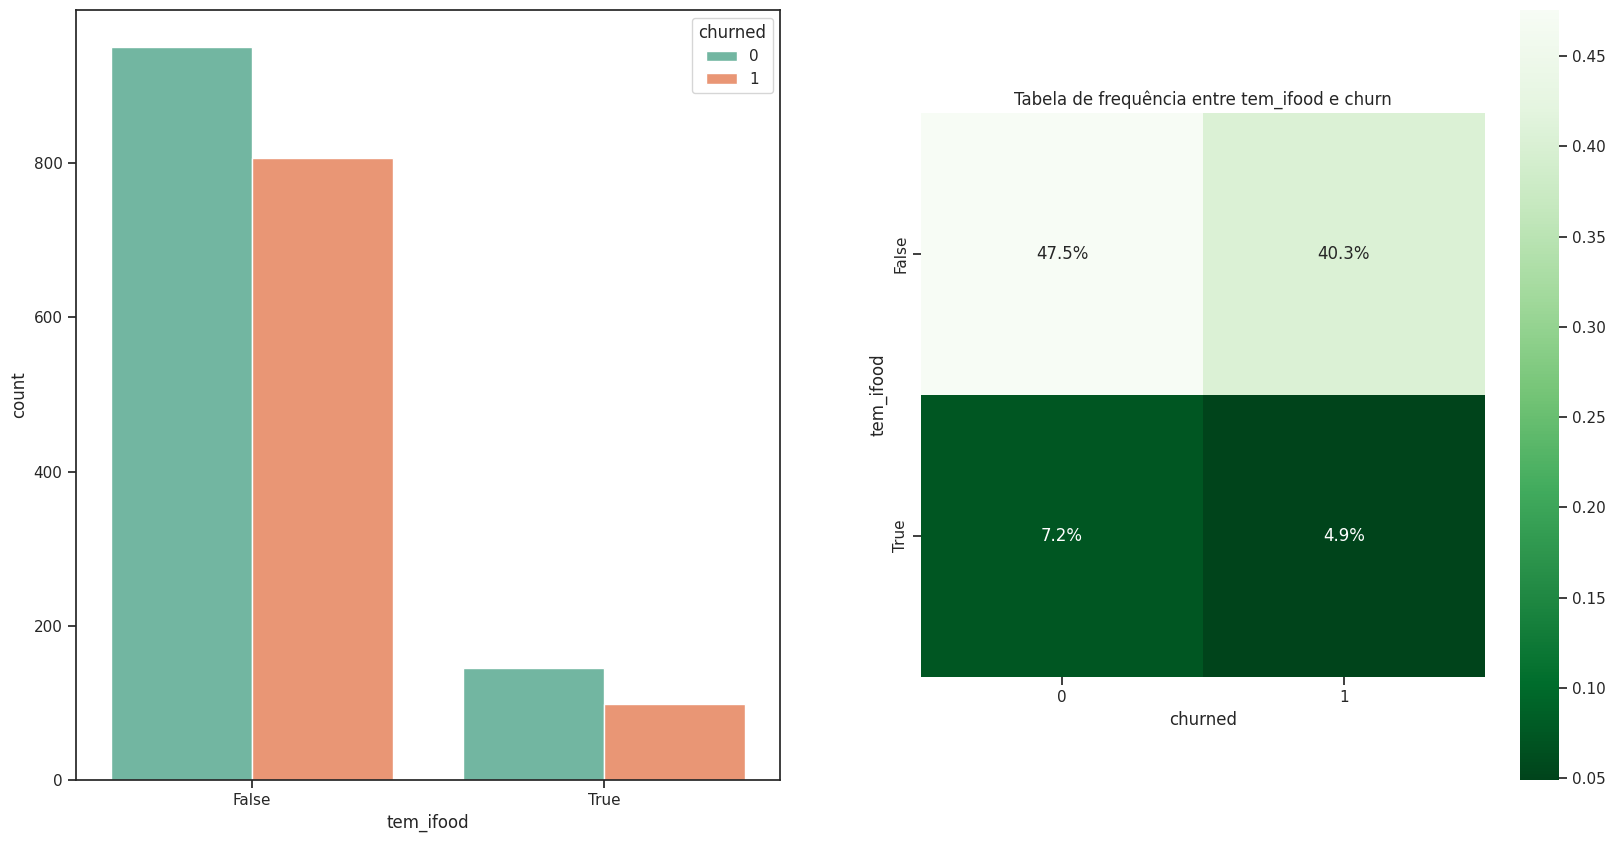

In [37]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads['tem_ifood'] = leads.ifood_faixa_preco.notna()

sb.countplot(data=leads, x='tem_ifood', hue='churned', ax=ax1)

ax2.set_title('Tabela de frequência entre tem_ifood e churn')
sb.heatmap(pd.crosstab(leads.tem_ifood, leads.churned, normalize=True), annot=True, fmt='.1%', square=True, cmap='Greens_r', ax=ax2)

de modo geral, quem tem ifood tem uma chance um pouco maior de não dar churn.

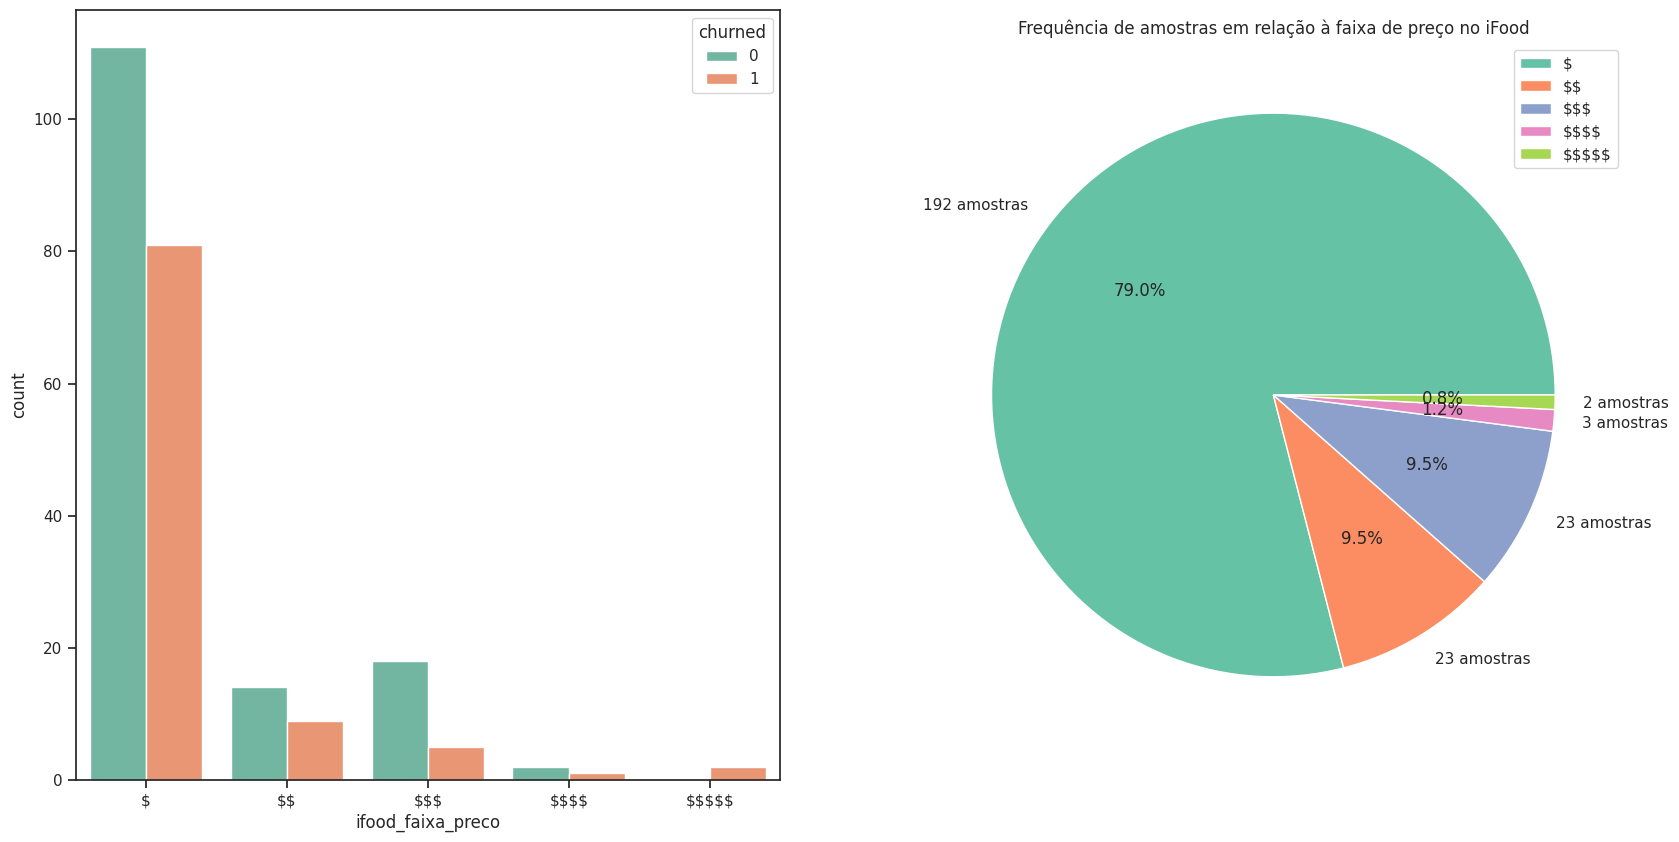

In [38]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

# Escapando os caracteres '$' para evitar erros com o matplotlib
leads.ifood_faixa_preco = leads.ifood_faixa_preco.apply(lambda x: x.replace('$', '\\$') if pd.notna(x) else x)
faixas = sorted(leads.ifood_faixa_preco.dropna().unique())

sb.countplot(data=leads, x='ifood_faixa_preco', hue='churned', order=faixas, ax=ax1)

contagem_de_faixas = leads.ifood_faixa_preco.value_counts()

ax2.set_title('Frequência de amostras em relação à faixa de preço no iFood')
ax2.pie(contagem_de_faixas, labels=[f'{contagem} amostras' for contagem in contagem_de_faixas], autopct='%.1f%%')
ax2.legend(faixas)

no geral dá pra ver que os pedidos no iFood são baratos: a faixa $ sozinha já é quase 80% da amostra e as faixas mais caras têm praticamente nada, só 2 e 3 clientes. Só que essa variável já tem poucas amostras de cara e dividindo ainda em 5 faixas de preço isso fica bem esparso, então não dá pra confiar muito no padrão da faixa em si. Faz mais sentido a gente tratar de maneira geral, sem se preocupar com a faixa de preço específica.

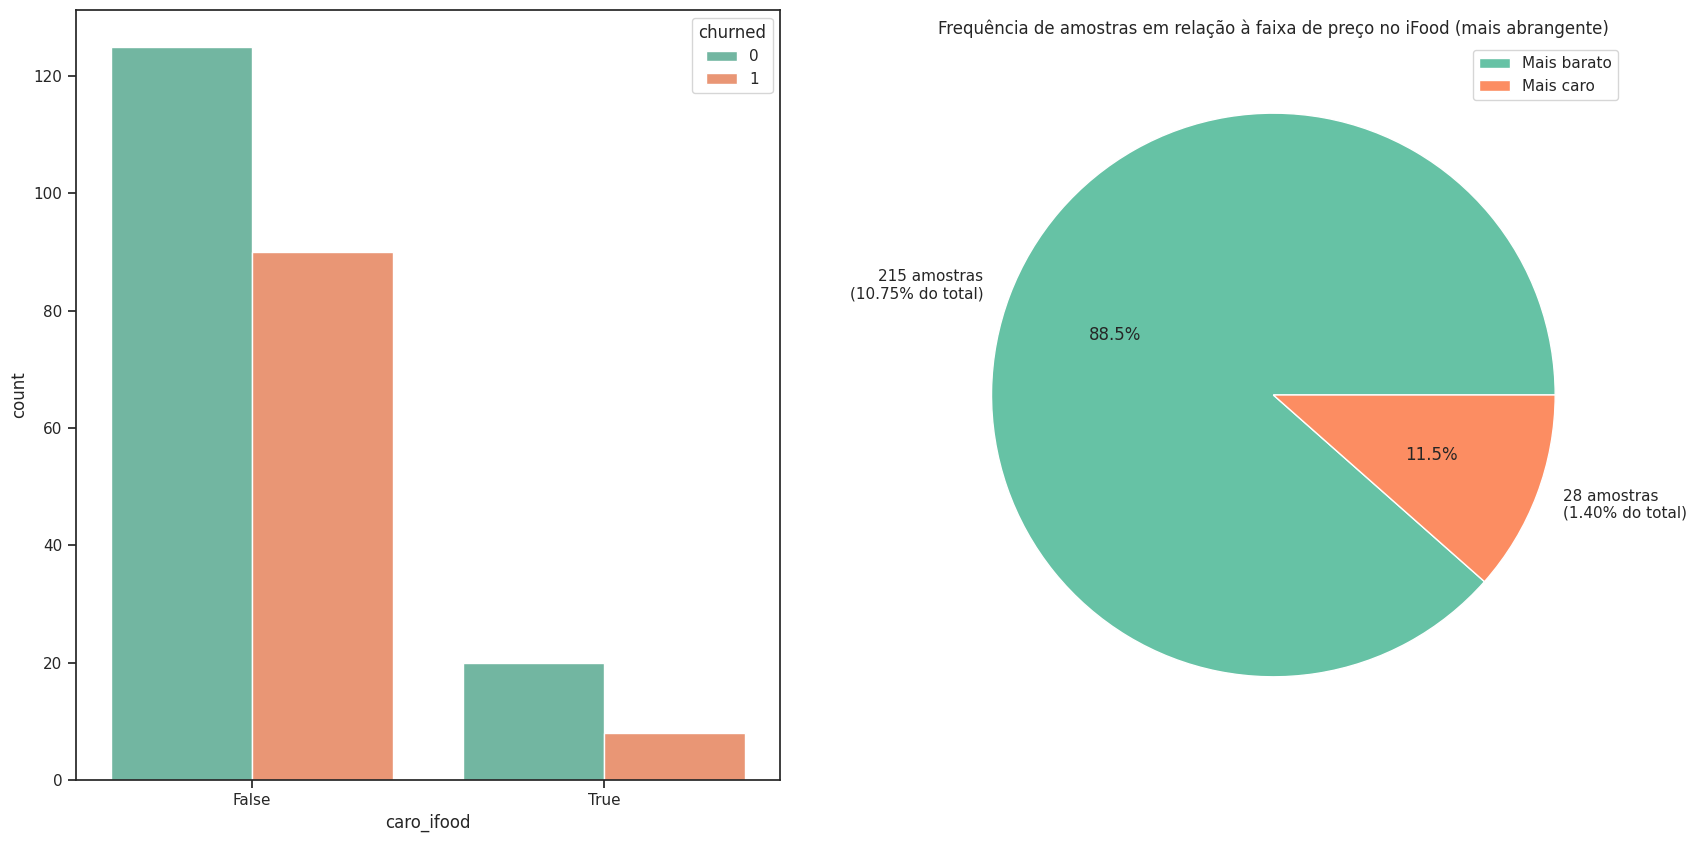

In [39]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads['caro_ifood'] = leads.ifood_faixa_preco.apply(lambda x: x if pd.isna(x) else len(x) >= len('\\$' * 3))
sb.countplot(data=leads, x='caro_ifood', hue='churned', ax=ax1)

contagem_mais_abrangente = leads.caro_ifood.value_counts()

ax2.set_title('Frequência de amostras em relação à faixa de preço no iFood (mais abrangente)')
ax2.pie(contagem_mais_abrangente, labels=[f'{contagem} amostras\n({100*contagem / leads.shape[0]:.2f}% do total)' for contagem in contagem_mais_abrangente], autopct='%.1f%%')
ax2.legend(['Mais barato', 'Mais caro'])

quem ta no ifood tem a mesma tendencia de dar menos churn, independente do preço. (a diferença eh menos gritante pro ifoodcaro=True pq tem menos amostras e algumas das categorias tem praticamente so amostra de um jeito ent enviesa) motivo pra gente descartar essa variavel

#### Google Maps


google_maps_avaliacao
(4.5, 5.0]    30
(3.0, 4.0]     7
(2.0, 3.0]     3
(1.0, 2.0]     3
(0.0, 1.0]     1
Name: count, dtype: int64

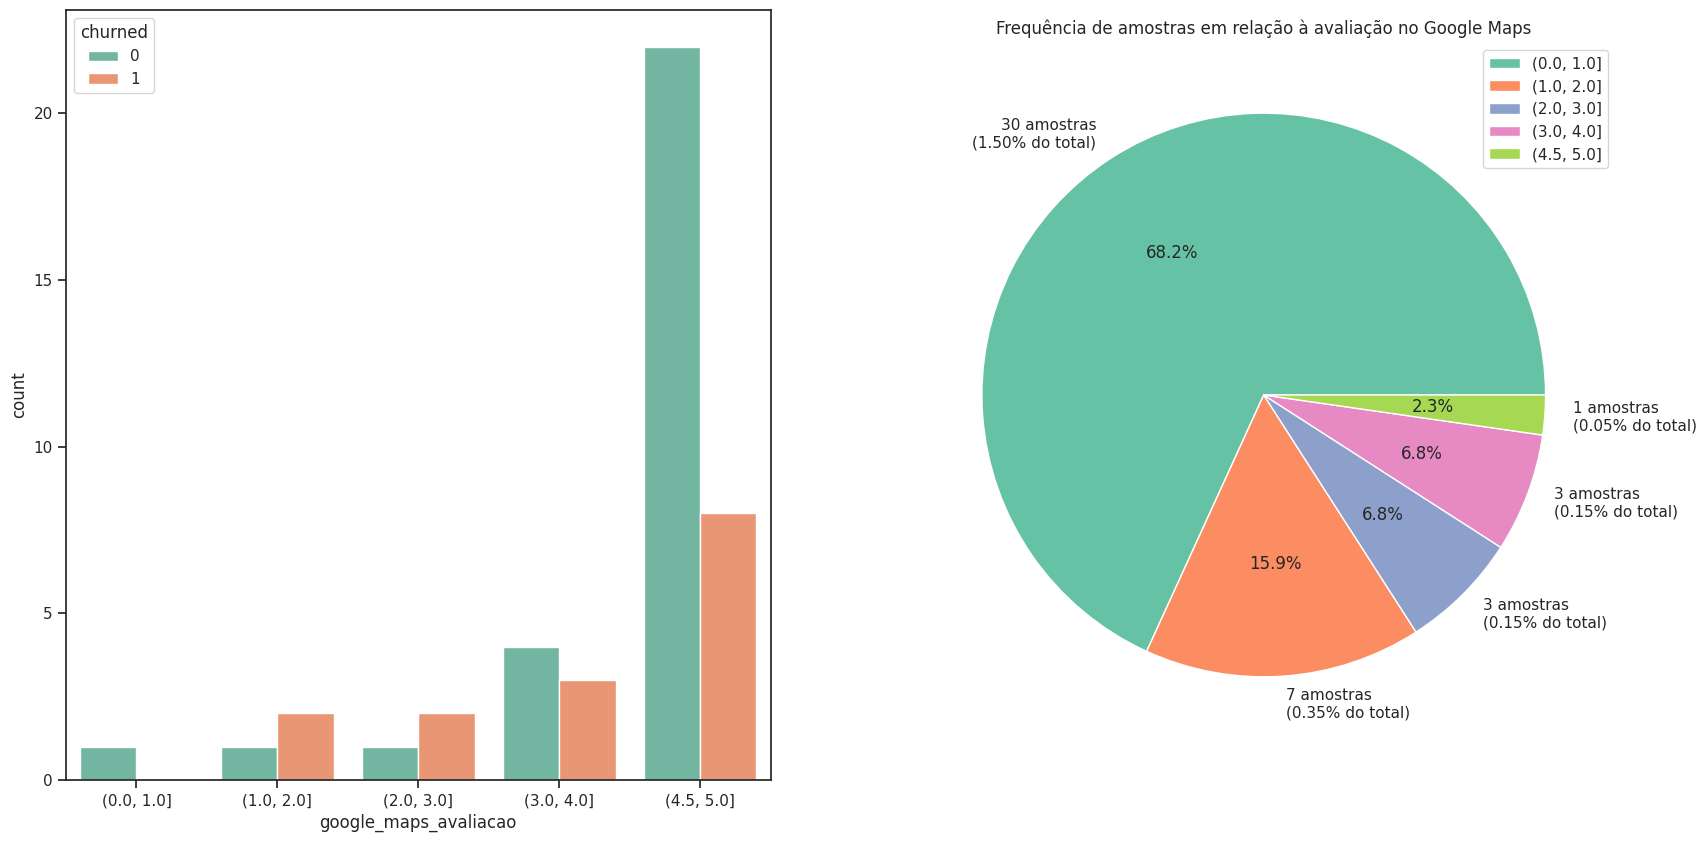

In [40]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

sb.countplot(data=leads, x='google_maps_avaliacao', hue='churned', order=sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True), ax=ax1)

contagem_de_faixas = leads.google_maps_avaliacao.value_counts()

ax2.set_title('Frequência de amostras em relação à avaliação no Google Maps')
ax2.pie(contagem_de_faixas, labels=[f'{contagem} amostras\n({100*contagem / leads.shape[0]:.2f}% do total)' for contagem in contagem_de_faixas], autopct='%.1f%%')
ax2.legend(sort_by_range(leads.google_maps_avaliacao.dropna().unique(), is_float=True))

contagem_de_faixas

tem quase nada com avaliacao, pq nao tem quase nada com google maps. apesar de ter um padrão promissor, achamos melhor nesse caso desconsiderar pelo tamanho minúsculo de amostras com esse campo em comparação com o todo.


<Axes: title={'center': 'Tabela de frequência entre google_maps_tem_website e churn'}, xlabel='churned', ylabel='google_maps_tem_website'>

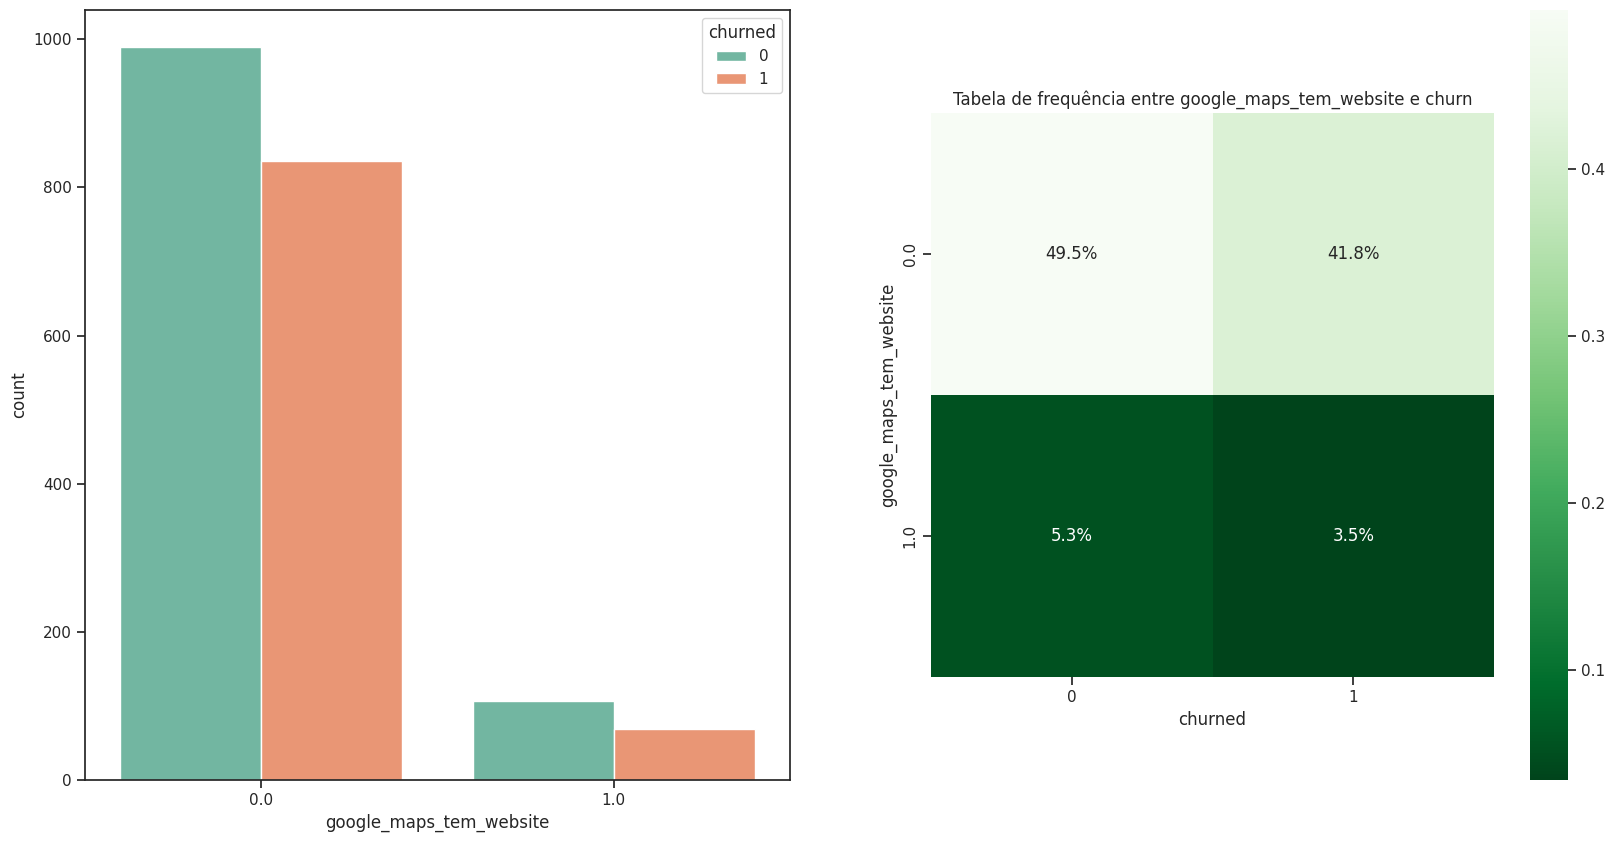

In [41]:
ax1, ax2 = plot.figure(figsize=(20, 10)).subplots(1, 2)

leads.google_maps_tem_website = leads.google_maps_tem_website.apply(lambda x: 0 if pd.isna(x) else x)

sb.countplot(data=leads, x='google_maps_tem_website', hue='churned', ax=ax1)

ax2.set_title('Tabela de frequência entre google_maps_tem_website e churn')
sb.heatmap(pd.crosstab(leads.google_maps_tem_website, leads.churned, normalize=True), annot=True, fmt='.1%', square=True, cmap='Greens_r', ax=ax2)

pode-se ver que no geral, podemos assumir que quem tem website tem chance ligeiramente menor de dar churn, se você comparar as porcentagens. isso é similar à questão do ifood

### 3.2 Comportamento de pedidos


aa